# 🌲 Ensemble Methods, Bias–Variance Trade-off & Regularization
### Bagging • Boosting (XGBoost, LightGBM) • Overfitting / Underfitting • L1 / L2 Regularization

**Is notebook mein kya hai?**

| Part | Topic | Key graphs |
|---|---|---|
| 1 | Bias–Variance Trade-off | Under/Good/Over fit, bias² vs variance U-curve, spaghetti plot |
| 2 | Overfitting & Underfitting | Validation curve, learning curves, decision boundaries |
| 3 | Regularization (L1 / L2) | Ridge vs Lasso fits, coefficient paths, L1-L2 geometry, sparsity |
| 4 | Bagging & Random Forest | Bootstrap 63.2 %, variance reduction, OOB score |
| 5 | Boosting (GB from scratch, AdaBoost, **XGBoost**, **LightGBM**) | Stage-wise fitting, learning curves, early stopping, speed, feature importance, ROC |
| 6 | Final comparison + Summary + Viva Q&A | Leaderboard |

> 💡 **Tip:** Notebook ko *Runtime → Run all* karke ek hi baar mein chala sakte ho (Google Colab / Jupyter). Poora run ~3–6 min leta hai.

In [ ]:
# Colab/Jupyter mein agar xgboost / lightgbm na ho to install ho jayega
import sys, subprocess
for pkg in ["xgboost", "lightgbm"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [ ]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.datasets import make_classification, make_regression, make_moons, load_breast_cancer
from sklearn.model_selection import (train_test_split, validation_curve, learning_curve)
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import (accuracy_score, roc_auc_score, log_loss, mean_squared_error,
                             ConfusionMatrixDisplay, RocCurveDisplay)

import xgboost as xgb
from xgboost import XGBClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.labelsize": 10, "legend.frameon": True})
RNG = 42
print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 📦 Dataset (classification, Parts 2, 4, 5, 6 mein use hoga)

Ek *noisy* synthetic dataset banate hain (30 features, 12 informative, 6 redundant, 5 % label noise) taaki overfitting clearly dikhe.
Split: **60 % train / 20 % validation / 20 % test** — validation set early stopping ke liye, test set sirf final evaluation ke liye.

In [ ]:
X_arr, y_arr = make_classification(n_samples=8000, n_features=30, n_informative=12, n_redundant=6,
                                   n_clusters_per_class=3, flip_y=0.05, class_sep=0.9, random_state=RNG)
feat_names = [f"f{i}" for i in range(30)]
X = pd.DataFrame(X_arr, columns=feat_names); y = pd.Series(y_arr)

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RNG)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RNG)
print(f"Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape} | class balance = {y.mean():.2f}")

# Leaderboard helper -------------------------------------------------
results, models = {}, {}
def evaluate(name, model):
    tr = accuracy_score(y_train, model.predict(X_train))
    te = accuracy_score(y_test,  model.predict(X_test))
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    results[name] = dict(Train_Acc=tr, Test_Acc=te, Gap=tr - te, Test_AUC=auc)
    models[name] = model
    return results[name]

Train (4800, 30) | Val (1600, 30) | Test (1600, 30) | class balance = 0.50


---
# Part 1️⃣ Bias–Variance Trade-off

Kisi bhi model ka expected test error (squared loss) 3 hisson mein tootta hai:

$$
\mathbb{E}\big[(y-\hat f(x))^2\big] \;=\; \underbrace{\big(\mathbb{E}[\hat f(x)]-f(x)\big)^2}_{\text{Bias}^2}
\;+\; \underbrace{\mathbb{E}\big[(\hat f(x)-\mathbb{E}[\hat f(x)])^2\big]}_{\text{Variance}}
\;+\; \underbrace{\sigma^2}_{\text{Irreducible noise}}
$$

| | **High Bias** | **High Variance** |
|---|---|---|
| Matlab | Model bahut *simple*, pattern miss karta hai | Model bahut *flexible*, noise ko bhi yaad kar leta hai |
| Result | **Underfitting** | **Overfitting** |
| Train error | High | Very low |
| Test error | High | High (train se bahut zyada) |
| Fix | Complex model, more features, kam regularization | More data, regularization, bagging, simpler model |

Neeche ek *known* function $f(x)=\sin(2\pi x)$ + Gaussian noise ($\sigma=0.3$) use karte hain, kyunki true $f$ pata ho tabhi bias aur variance **measure** kar sakte hain.

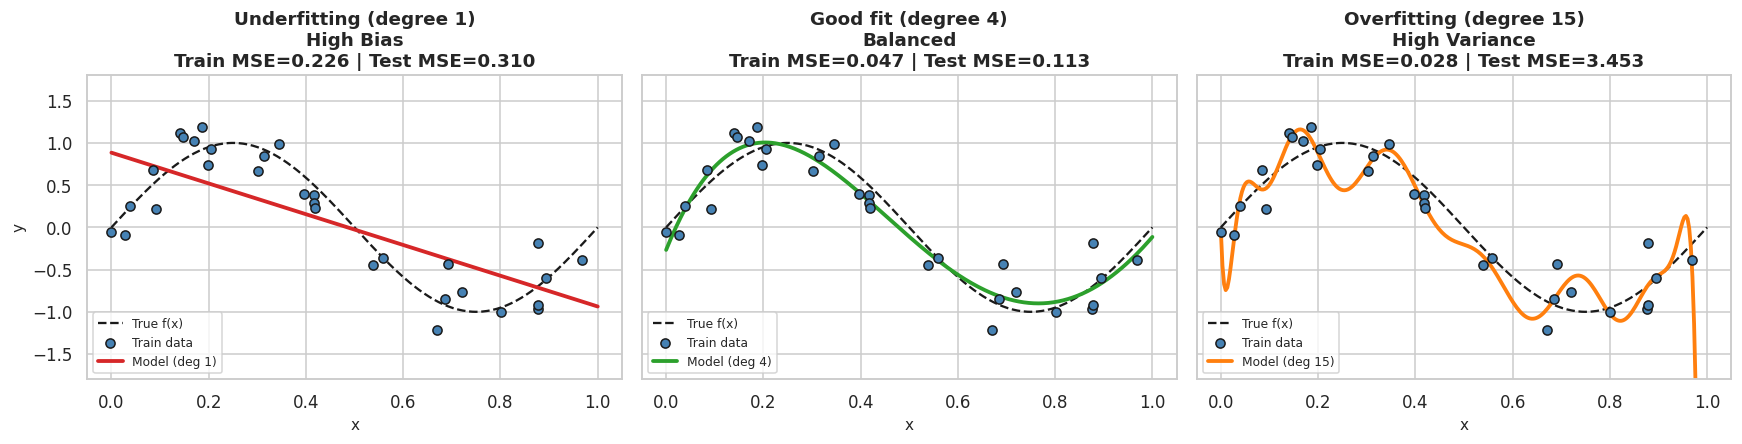

In [ ]:
SIGMA = 0.3
def f_true(x): return np.sin(2 * np.pi * x)

def make_data(n=30, noise=SIGMA, seed=0):
    r = np.random.RandomState(seed)
    x = np.sort(r.rand(n)); y = f_true(x) + r.randn(n) * noise
    return x, y

def poly_reg(deg, reg=None):
    return make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(),
                         reg if reg is not None else LinearRegression())

x_grid = np.linspace(0, 1, 300)
x_tr, y_tr = make_data(30, seed=1)
x_te, y_te = make_data(500, seed=999)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, d, title, col in zip(axes, [1, 4, 15],
        ["Underfitting (degree 1)\nHigh Bias", "Good fit (degree 4)\nBalanced", "Overfitting (degree 15)\nHigh Variance"],
        ["#d62728", "#2ca02c", "#ff7f0e"]):
    m = poly_reg(d).fit(x_tr[:, None], y_tr)
    tr_mse = mean_squared_error(y_tr, m.predict(x_tr[:, None]))
    te_mse = mean_squared_error(y_te, m.predict(x_te[:, None]))
    ax.plot(x_grid, f_true(x_grid), "k--", lw=1.5, label="True f(x)")
    ax.scatter(x_tr, y_tr, c="steelblue", edgecolor="k", s=36, label="Train data", zorder=3)
    ax.plot(x_grid, m.predict(x_grid[:, None]), color=col, lw=2.5, label=f"Model (deg {d})")
    ax.set_title(f"{title}\nTrain MSE={tr_mse:.3f} | Test MSE={te_mse:.3f}")
    ax.set_ylim(-1.8, 1.8); ax.set_xlabel("x"); ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("y")
plt.tight_layout(); plt.show()

### 🔬 Bias² aur Variance ko actually *measure* karte hain
Idea: **200 alag-alag training sets** banao (har ek 40 points), har par model fit karo, aur same `x_grid` par predictions compare karo.
- **Bias²** = (average prediction − true f)² → model ki *systematic* galti
- **Variance** = predictions ka spread → model training set ke saath kitna *hilta* hai

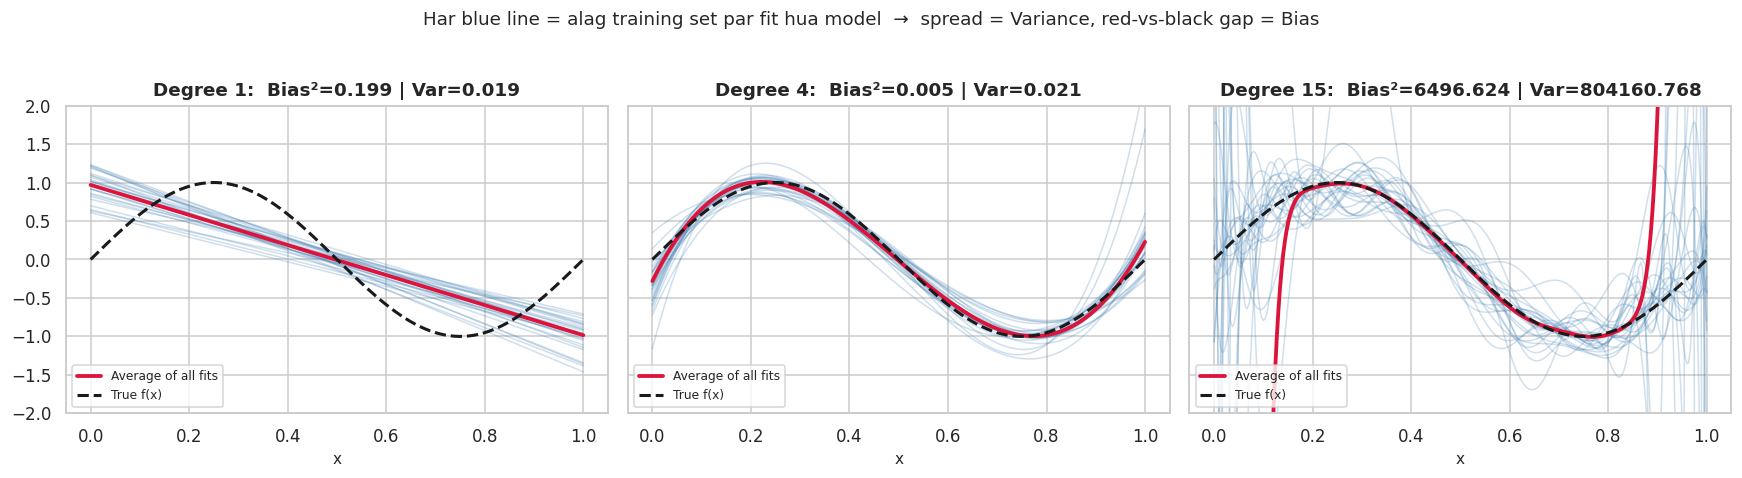

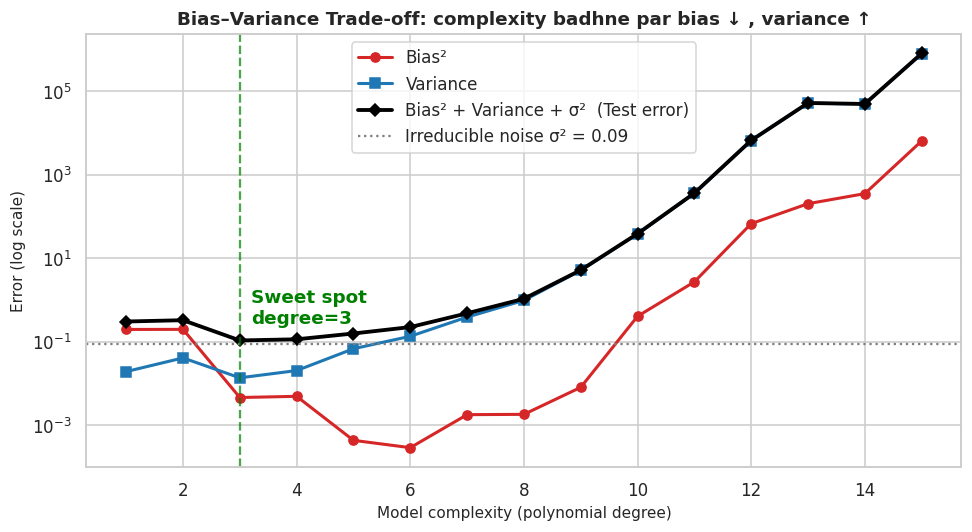

degree,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
bias2,0.1988,0.1999,0.0047,0.0050,0.0004,0.0003,0.0018,0.0018,0.0082,0.4109,2.7474,68.0188,204.6165,356.3668,6496.6238
variance,0.0195,0.0414,0.0138,0.0206,0.0686,0.1364,0.3931,0.9873,5.1518,38.6019,363.3978,6639.8916,52636.8931,49743.6072,804160.7678
expected_test_error,0.3083,0.3313,0.1085,0.1156,0.1591,0.2267,0.4849,1.0791,5.2499,39.1028,366.2352,6708.0005,52841.5996,50100.0640,810657.4816


In [ ]:
N_SIM, N_TRAIN = 200, 40
degrees = list(range(1, 16))
preds, rows = {}, []
for d in degrees:
    P = np.empty((N_SIM, len(x_grid)))
    for s in range(N_SIM):
        xs, ys = make_data(N_TRAIN, seed=1000 + s)
        P[s] = poly_reg(d).fit(xs[:, None], ys).predict(x_grid[:, None])
    preds[d] = P
    bias2 = np.mean((P.mean(0) - f_true(x_grid)) ** 2)
    var = np.mean(P.var(0))
    rows.append((d, bias2, var, bias2 + var + SIGMA ** 2))
bv = pd.DataFrame(rows, columns=["degree", "bias2", "variance", "expected_test_error"])

# ---- Spaghetti plots: 25 alag datasets, 25 alag fits ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, d in zip(axes, [1, 4, 15]):
    for p in preds[d][:25]:
        ax.plot(x_grid, p, color="steelblue", alpha=.25, lw=1)
    ax.plot(x_grid, preds[d].mean(0), color="crimson", lw=2.5, label="Average of all fits")
    ax.plot(x_grid, f_true(x_grid), "k--", lw=2, label="True f(x)")
    r = bv[bv.degree == d].iloc[0]
    ax.set_title(f"Degree {d}:  Bias²={r.bias2:.3f} | Var={r.variance:.3f}")
    ax.set_ylim(-2, 2); ax.set_xlabel("x"); ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Har blue line = alag training set par fit hua model  →  spread = Variance, red-vs-black gap = Bias",
             y=1.03, fontsize=12)
plt.tight_layout(); plt.show()

# ---- The famous U-curve ----
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(bv.degree, bv.bias2, "o-", color="#d62728", lw=2, label="Bias²")
ax.plot(bv.degree, bv.variance, "s-", color="#1f77b4", lw=2, label="Variance")
ax.plot(bv.degree, bv.expected_test_error, "D-", color="black", lw=2.5, label="Bias² + Variance + σ²  (Test error)")
ax.axhline(SIGMA ** 2, color="gray", ls=":", label=f"Irreducible noise σ² = {SIGMA**2:.2f}")
best = bv.loc[bv.expected_test_error.idxmin(), "degree"]
ax.axvline(best, color="green", ls="--", alpha=.7); ax.text(best + .2, bv.expected_test_error.min() * 2.5, f"Sweet spot\ndegree={int(best)}", color="green", fontweight="bold")
ax.set_yscale("log"); ax.set_xlabel("Model complexity (polynomial degree)"); ax.set_ylabel("Error (log scale)")
ax.set_title("Bias–Variance Trade-off: complexity badhne par bias ↓ , variance ↑")
ax.legend(); plt.tight_layout(); plt.show()
display(bv.round(4).set_index("degree").T)

**📌 Observation**
- Degree 1: bias bahut high (line sine ko capture hi nahi kar sakti) par variance ≈ 0 → **underfit**.
- Degree 15: bias ≈ 0 par variance explode → **overfit**.
- Beech mein (≈ degree 3–5) total error minimum — yehi *sweet spot* hai. Hamara goal: **bias aur variance ko saath mein kam** rakhna.

---
# Part 2️⃣ Overfitting vs Underfitting

| | Underfitting | Good fit | Overfitting |
|---|---|---|---|
| Train score | Low | High | Very high (≈100 %) |
| Validation score | Low | High | Much lower than train |
| Gap (train − val) | Small | Small | **Large** |
| Causes | Model too simple, too few features, too much regularization, too few epochs | – | Model too complex, too little data, noisy labels, no regularization, too many epochs |
| Fixes | ↑ complexity, feature engineering, ↓ regularization, train longer | – | More data, regularization, early stopping, pruning, dropout, bagging, cross-validation |

### 🩺 Diagnose karne ke 3 tareeke
1. **Validation curve** – ek hyperparameter (complexity) badalte hue train vs val score
2. **Learning curve** – training-set size badalte hue train vs val score
3. **Train–test gap** – sabse simple check

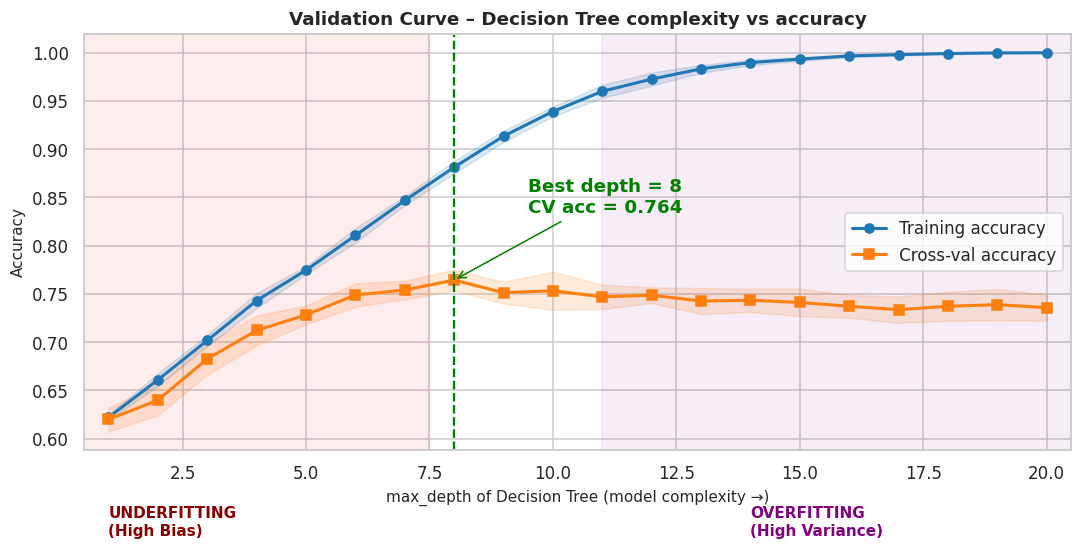

max_depth=1  → train 0.622, val 0.620  (underfit)
max_depth=8  → train 0.881, val 0.764  (good)
max_depth=20 → train 1.000, val 0.736  (overfit, gap = 0.264)


In [ ]:
depths = np.arange(1, 21)
tr_sc, va_sc = validation_curve(DecisionTreeClassifier(random_state=RNG), X_train, y_train,
                                param_name="max_depth", param_range=depths, cv=5,
                                scoring="accuracy", n_jobs=-1)
tr_m, tr_s, va_m, va_s = tr_sc.mean(1), tr_sc.std(1), va_sc.mean(1), va_sc.std(1)
best_d = depths[va_m.argmax()]

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(depths, tr_m, "o-", color="#1f77b4", lw=2, label="Training accuracy")
ax.fill_between(depths, tr_m - tr_s, tr_m + tr_s, color="#1f77b4", alpha=.15)
ax.plot(depths, va_m, "s-", color="#ff7f0e", lw=2, label="Cross-val accuracy")
ax.fill_between(depths, va_m - va_s, va_m + va_s, color="#ff7f0e", alpha=.15)
ax.axvspan(0.5, best_d - 0.5, color="red", alpha=.07); ax.axvspan(best_d + 3, 20.5, color="purple", alpha=.07)
ax.axvline(best_d, color="green", ls="--");
ax.text(1, 0.5, "UNDERFITTING\n(High Bias)", color="darkred", fontsize=10, fontweight="bold")
ax.text(14, 0.5, "OVERFITTING\n(High Variance)", color="purple", fontsize=10, fontweight="bold")
ax.annotate(f"Best depth = {best_d}\nCV acc = {va_m.max():.3f}", xy=(best_d, va_m.max()), xytext=(best_d + 1.5, va_m.max() + .07),
            arrowprops=dict(arrowstyle="->", color="green"), color="green", fontweight="bold")
ax.set_xlabel("max_depth of Decision Tree (model complexity →)"); ax.set_ylabel("Accuracy"); ax.set_xlim(.5, 20.5)
ax.set_title("Validation Curve – Decision Tree complexity vs accuracy"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()
print(f"max_depth=1  → train {tr_m[0]:.3f}, val {va_m[0]:.3f}  (underfit)")
print(f"max_depth={best_d}  → train {tr_m[best_d-1]:.3f}, val {va_m[best_d-1]:.3f}  (good)")
print(f"max_depth=20 → train {tr_m[-1]:.3f}, val {va_m[-1]:.3f}  (overfit, gap = {tr_m[-1]-va_m[-1]:.3f})")

### 🗺️ Decision boundaries (visual intuition) + 📈 Learning curves
`make_moons` (2-D) par teen trees: depth 1 (underfit), depth 4 (good), depth ∞ (overfit). Neeche learning curves se pata chalta hai ki **zyada data** kab kaam karega:
- *High bias*: train & val dono low aur **converge** ho jaate hain → zyada data se faayda nahi, model complex banao.
- *High variance*: train high, val low, **bada gap** → zyada data / regularization se faayda.

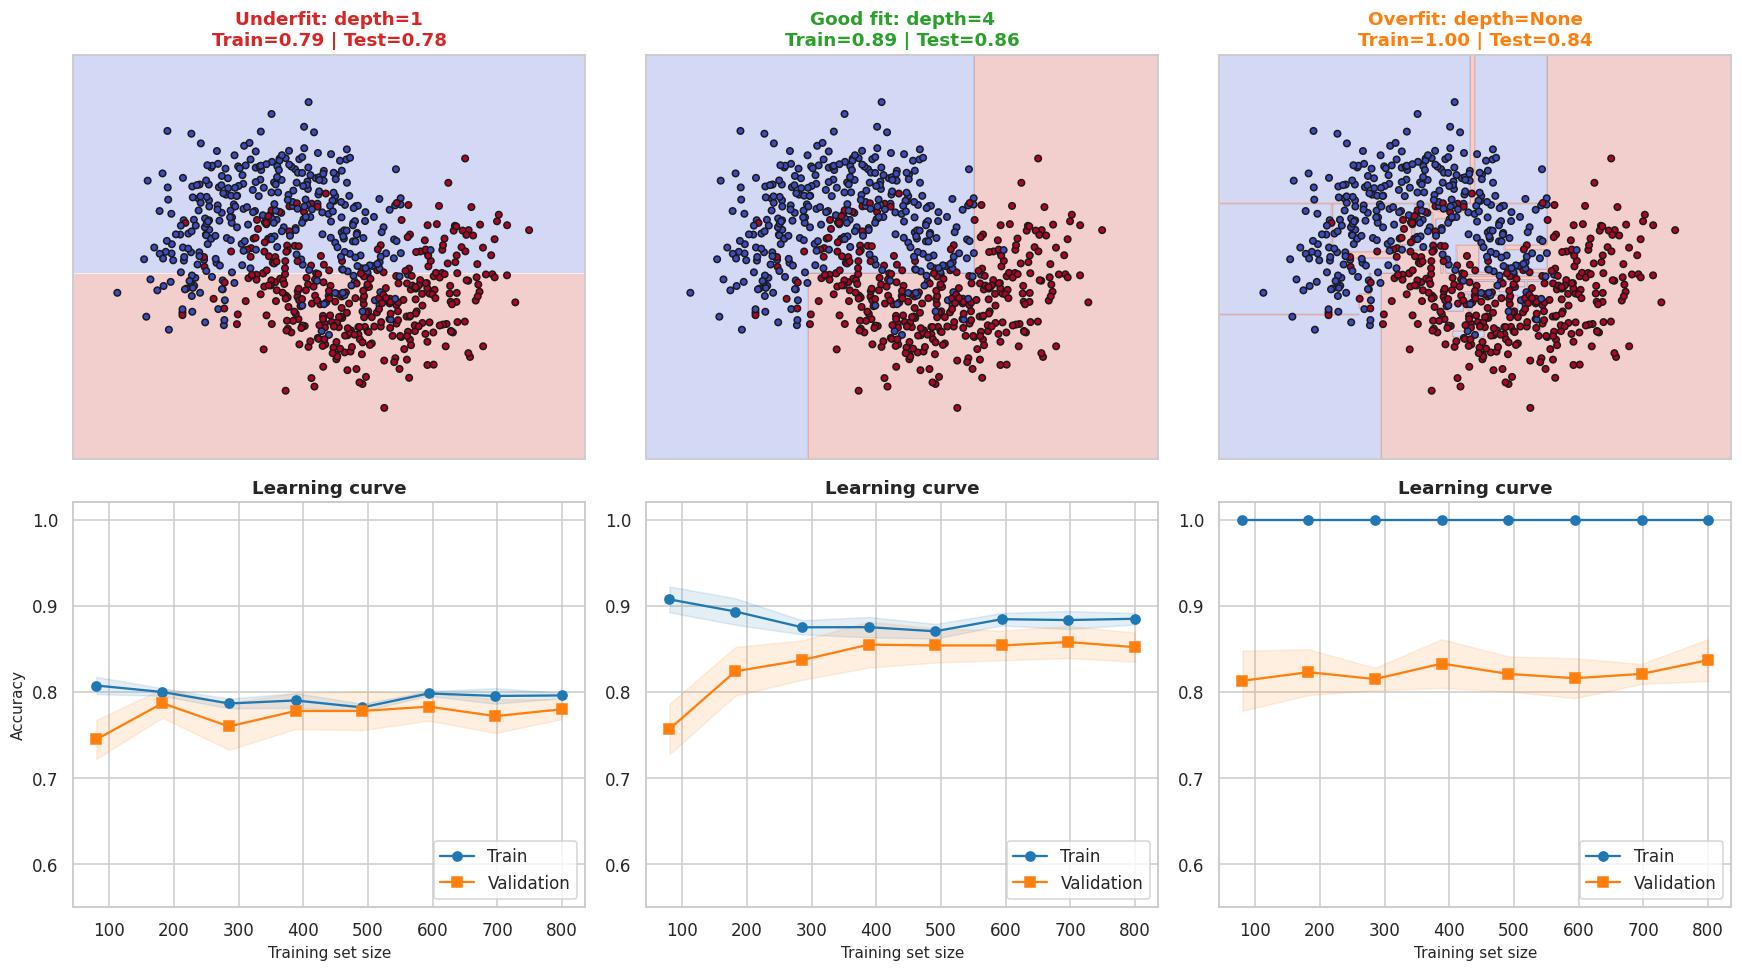

In [ ]:
Xm, ym = make_moons(n_samples=1000, noise=0.35, random_state=RNG)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=RNG)
configs = [("Underfit: depth=1", 1, "#d62728"), ("Good fit: depth=4", 4, "#2ca02c"), ("Overfit: depth=None", None, "#ff7f0e")]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
xx, yy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 300),
                     np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 300))
for j, (title, d, col) in enumerate(configs):
    clf = DecisionTreeClassifier(max_depth=d, random_state=RNG).fit(Xm_tr, ym_tr)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax = axes[0, j]
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm")
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap="coolwarm", edgecolor="k", s=18)
    ax.set_title(f"{title}\nTrain={clf.score(Xm_tr, ym_tr):.2f} | Test={clf.score(Xm_te, ym_te):.2f}", color=col)
    ax.set_xticks([]); ax.set_yticks([])
    # learning curve
    sizes, trs, vas = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=RNG), Xm, ym,
                                     train_sizes=np.linspace(.1, 1, 8), cv=5, n_jobs=-1)
    ax = axes[1, j]
    ax.plot(sizes, trs.mean(1), "o-", color="#1f77b4", label="Train")
    ax.plot(sizes, vas.mean(1), "s-", color="#ff7f0e", label="Validation")
    ax.fill_between(sizes, trs.mean(1) - trs.std(1), trs.mean(1) + trs.std(1), alpha=.12, color="#1f77b4")
    ax.fill_between(sizes, vas.mean(1) - vas.std(1), vas.mean(1) + vas.std(1), alpha=.12, color="#ff7f0e")
    ax.set_ylim(.55, 1.02); ax.set_xlabel("Training set size"); ax.set_title("Learning curve"); ax.legend(loc="lower right")
axes[1, 0].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

### ✅ Overfitting rokne ke practical tarike (cheat-sheet)
1. **More / better data**, data augmentation  2. **Simpler model** (kam depth, kam leaves)  3. **Regularization** (L1/L2, dropout)
4. **Early stopping** (validation loss badhne par ruk jao)  5. **Ensembling** – Bagging variance ghatata hai  6. **Cross-validation** se honest estimate
7. **Feature selection** – noisy features hatao  8. **Pruning** (trees) / `min_samples_leaf`, `min_child_weight`

---
# Part 3️⃣ Regularization (L1 / L2)

Regularization = loss function mein **penalty** jodna taaki weights chhote rahein → model *smooth / simple* hota hai → variance kam, generalization behtar.

$$
J(\mathbf{w}) = \underbrace{\frac{1}{n}\sum_i (y_i-\hat y_i)^2}_{\text{data loss}} \;+\; \lambda\,\underbrace{\Omega(\mathbf{w})}_{\text{penalty}}
\qquad
\Omega_{L2}=\sum_j w_j^2 \;(\text{Ridge}),\quad \Omega_{L1}=\sum_j |w_j| \;(\text{Lasso})
$$

| | **L2 – Ridge** | **L1 – Lasso** |
|---|---|---|
| Penalty | $\lambda \sum w_j^2$ | $\lambda \sum \lvert w_j\rvert$ |
| Effect | Weights ko **shrink** karta hai (zero ke paas, par exactly zero nahi) | Kuch weights **exactly 0** → automatic **feature selection** (sparsity) |
| Best when | Saare features thoda-thoda useful, multicollinearity | Kam features important, high-dimensional data |
| Geometry | Circle (smooth) | Diamond (corners on axes) |
| Boosting mein | XGBoost `reg_lambda`, LightGBM `reg_lambda` / `lambda_l2` | XGBoost `reg_alpha`, LightGBM `reg_alpha` / `lambda_l1` |

$\lambda$ (sklearn mein `alpha`) bada → simple model (↑ bias, ↓ variance). $\lambda$ chhota → complex model (↓ bias, ↑ variance). **Yahan bhi bias–variance trade-off hai!**

### 3.1 Degree-15 polynomial: bina regularization vs Ridge vs Lasso

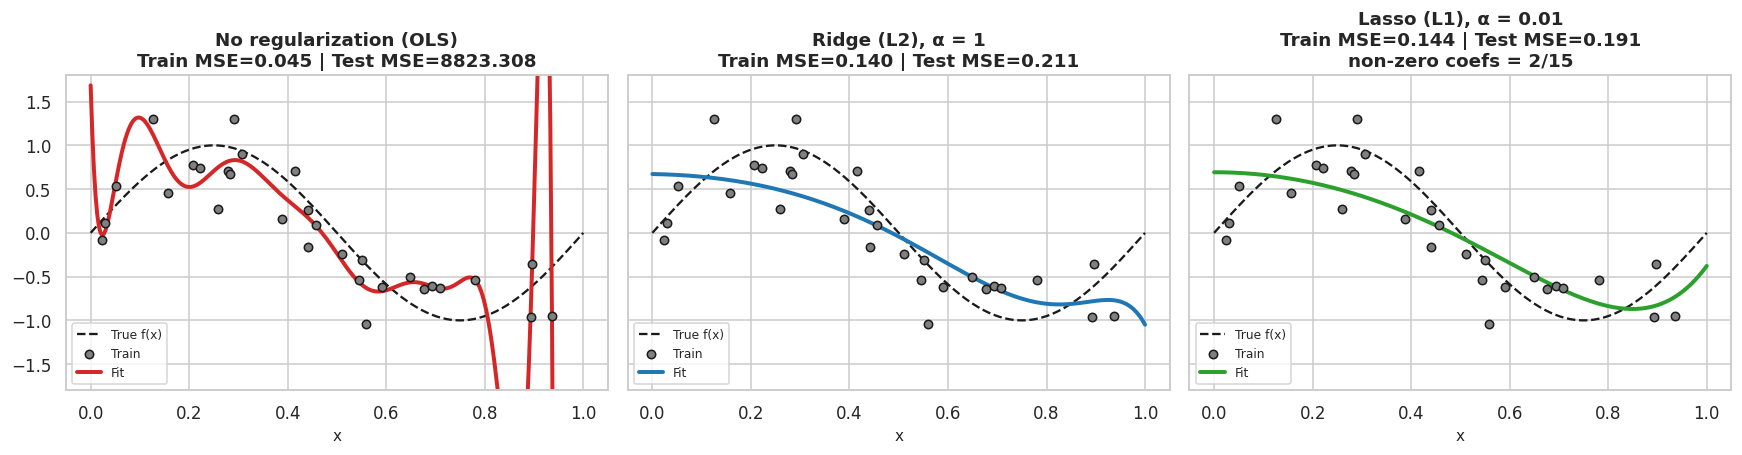

In [ ]:
x_tr, y_tr = make_data(30, seed=3)
x_te, y_te = make_data(500, seed=99)
regs = {"No regularization (OLS)": LinearRegression(),
        "Ridge (L2), α = 1": Ridge(alpha=1.0),
        "Lasso (L1), α = 0.01": Lasso(alpha=0.01, max_iter=200000)}
cols = ["#d62728", "#1f77b4", "#2ca02c"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, (name, reg), c in zip(axes, regs.items(), cols):
    m = poly_reg(15, reg).fit(x_tr[:, None], y_tr)
    te = mean_squared_error(y_te, m.predict(x_te[:, None])); tr = mean_squared_error(y_tr, m.predict(x_tr[:, None]))
    ax.plot(x_grid, f_true(x_grid), "k--", label="True f(x)")
    ax.scatter(x_tr, y_tr, c="gray", edgecolor="k", s=30, zorder=3, label="Train")
    ax.plot(x_grid, m.predict(x_grid[:, None]), color=c, lw=2.6, label="Fit")
    extra = ""
    if name.startswith("Lasso"):
        extra = f"\nnon-zero coefs = {(m[-1].coef_ != 0).sum()}/15"
    ax.set_title(f"{name}\nTrain MSE={tr:.3f} | Test MSE={te:.3f}{extra}")
    ax.set_ylim(-1.8, 1.8); ax.legend(loc="lower left", fontsize=8); ax.set_xlabel("x")
plt.tight_layout(); plt.show()

### 3.2 Regularization strength (α) vs error — 15 alag datasets par average

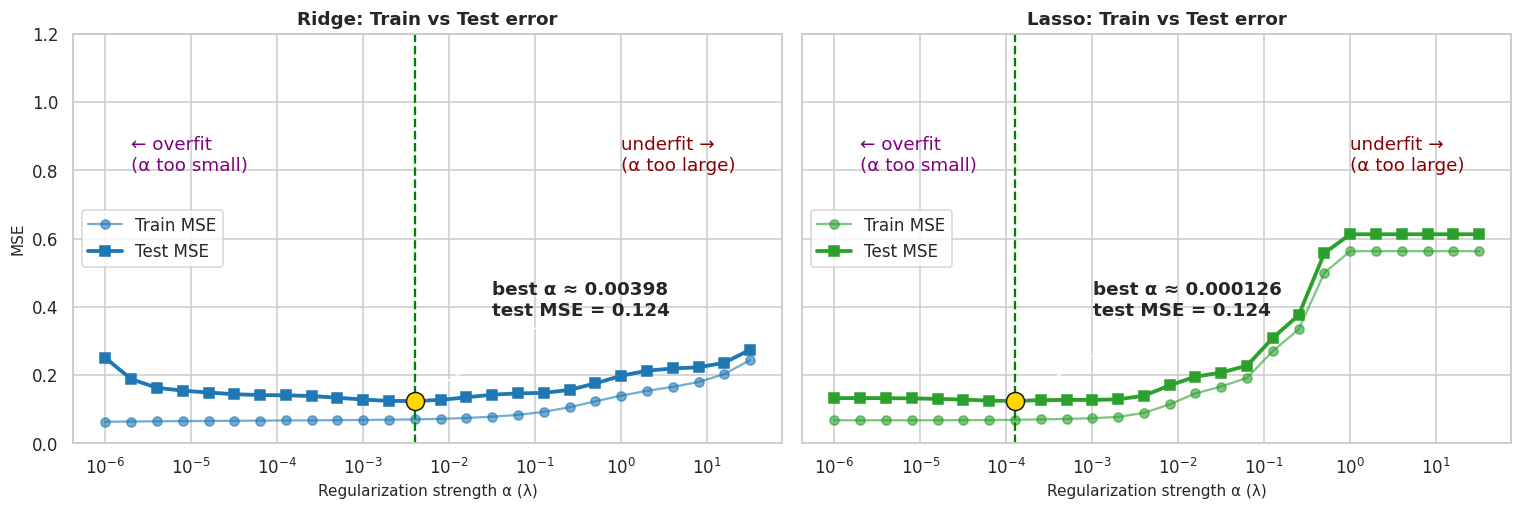

In [ ]:
alphas = np.logspace(-6, 1.5, 26)
x_te, y_te = make_data(500, seed=99)
curves = {"Ridge": [], "Lasso": []}
for a in alphas:
    for nm, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
        trs, tes = [], []
        for s in range(15):
            xs, ys = make_data(30, seed=500 + s)
            kw = dict(alpha=a, max_iter=50000) if nm == "Lasso" else dict(alpha=a)
            m = poly_reg(15, cls(**kw)).fit(xs[:, None], ys)
            trs.append(mean_squared_error(ys, m.predict(xs[:, None])))
            tes.append(mean_squared_error(y_te, m.predict(x_te[:, None])))
        curves[nm].append((np.mean(trs), np.mean(tes)))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, nm, c in zip(axes, ["Ridge", "Lasso"], ["#1f77b4", "#2ca02c"]):
    arr = np.array(curves[nm])
    ax.semilogx(alphas, arr[:, 0], "o-", color=c, alpha=.6, label="Train MSE")
    ax.semilogx(alphas, arr[:, 1], "s-", color=c, lw=2.5, label="Test MSE")
    bi = arr[:, 1].argmin()
    ax.axvline(alphas[bi], color="green", ls="--"); ax.scatter(alphas[bi], arr[bi, 1], s=140, color="gold", edgecolor="k", zorder=5)
    ax.annotate(f"best α ≈ {alphas[bi]:.3g}\ntest MSE = {arr[bi,1]:.3f}", (alphas[bi], arr[bi, 1]),
                xytext=(alphas[bi] * 8, arr[bi, 1] + .25), arrowprops=dict(arrowstyle="->"), fontweight="bold")
    ax.set_ylim(0, 1.2)
    ax.text(alphas[0] * 2, 0.8, "← overfit\n(α too small)", color="purple")
    ax.text(alphas[-6], 0.8, "underfit →\n(α too large)", color="darkred")
    ax.set_xlabel("Regularization strength α (λ)"); ax.set_title(f"{nm}: Train vs Test error"); ax.legend(loc="center left")
axes[0].set_ylabel("MSE"); axes[0].set_ylim(0, 1.2)
plt.tight_layout(); plt.show()

### 3.3 Coefficient paths — Ridge *shrink* karta hai, Lasso *zero* karta hai
20 features me se sirf **5 informative** (red), baaki 15 pure noise (grey).

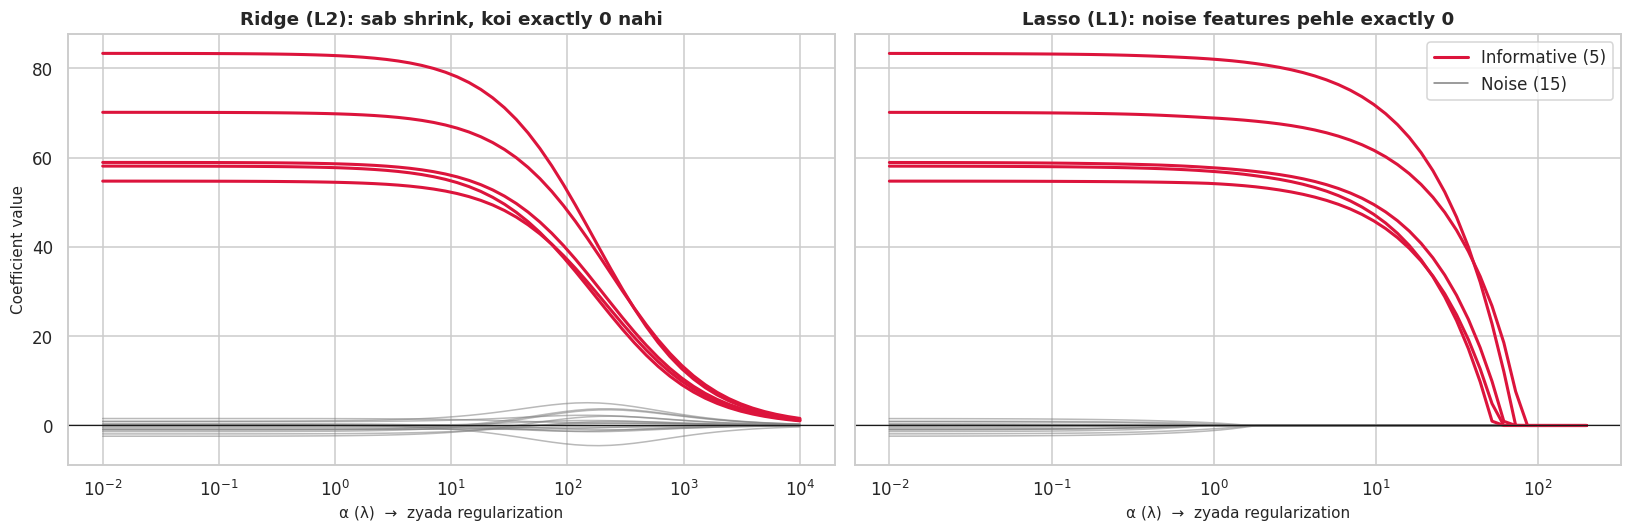

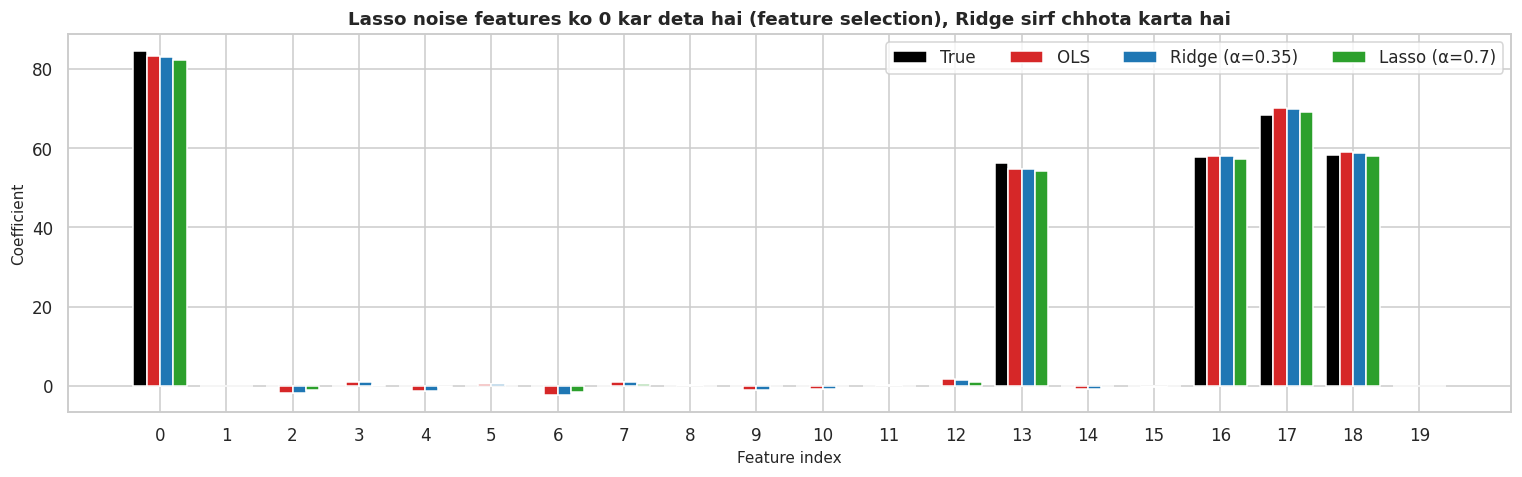

Exactly-zero coefficients → OLS: 0 | Ridge: 0 | Lasso: 7  (true zeros = 15)


In [ ]:
Xr, yr, coef_true = make_regression(n_samples=200, n_features=20, n_informative=5, noise=15, coef=True, random_state=0)
inform = coef_true != 0
ridge_alphas = np.logspace(-2, 4, 60); lasso_alphas = np.logspace(-2, 2.3, 60)
ridge_path = np.array([Ridge(alpha=a).fit(Xr, yr).coef_ for a in ridge_alphas])
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xr, yr).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, path, al, name in [(axes[0], ridge_path, ridge_alphas, "Ridge (L2): sab shrink, koi exactly 0 nahi"),
                           (axes[1], lasso_path, lasso_alphas, "Lasso (L1): noise features pehle exactly 0")]:
    for j in range(20):
        ax.semilogx(al, path[:, j], color="crimson" if inform[j] else "gray", lw=2 if inform[j] else 1, alpha=1 if inform[j] else .55)
    ax.axhline(0, color="k", lw=.8); ax.set_title(name); ax.set_xlabel("α (λ)  →  zyada regularization")
axes[0].set_ylabel("Coefficient value")
from matplotlib.lines import Line2D
axes[1].legend(handles=[Line2D([0], [0], color="crimson", lw=2, label="Informative (5)"),
                        Line2D([0], [0], color="gray", lw=1, label="Noise (15)")], loc="upper right")
plt.tight_layout(); plt.show()

# CV se best alpha + coefficient comparison
ols = LinearRegression().fit(Xr, yr).coef_
rdg = RidgeCV(alphas=np.logspace(-2, 3, 40)).fit(Xr, yr)
las = LassoCV(alphas=np.logspace(-2, 1, 40), cv=5, max_iter=50000).fit(Xr, yr)
idx = np.arange(20); w = .2
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(idx - 1.5 * w, coef_true, w, label="True", color="black")
ax.bar(idx - .5 * w, ols, w, label="OLS", color="#d62728")
ax.bar(idx + .5 * w, rdg.coef_, w, label=f"Ridge (α={rdg.alpha_:.2g})", color="#1f77b4")
ax.bar(idx + 1.5 * w, las.coef_, w, label=f"Lasso (α={las.alpha_:.2g})", color="#2ca02c")
ax.set_xticks(idx); ax.set_xlabel("Feature index"); ax.set_ylabel("Coefficient"); ax.legend(ncol=4)
ax.set_title("Lasso noise features ko 0 kar deta hai (feature selection), Ridge sirf chhota karta hai")
plt.tight_layout(); plt.show()
print(f"Exactly-zero coefficients → OLS: {(ols==0).sum()} | Ridge: {(rdg.coef_==0).sum()} | Lasso: {(las.coef_==0).sum()}  (true zeros = {(~inform).sum()})")

### 3.4 Geometry: Lasso corners par kyun "touch" karta hai?
Loss ke ellipse-contours aur constraint region ($|w_1|+|w_2|\le t$ ya $w_1^2+w_2^2\le t$) jahan pehli baar milte hain wahi solution hai. Diamond ke **corner axes par** hain → solution aksar $w_2=0$ (sparse).

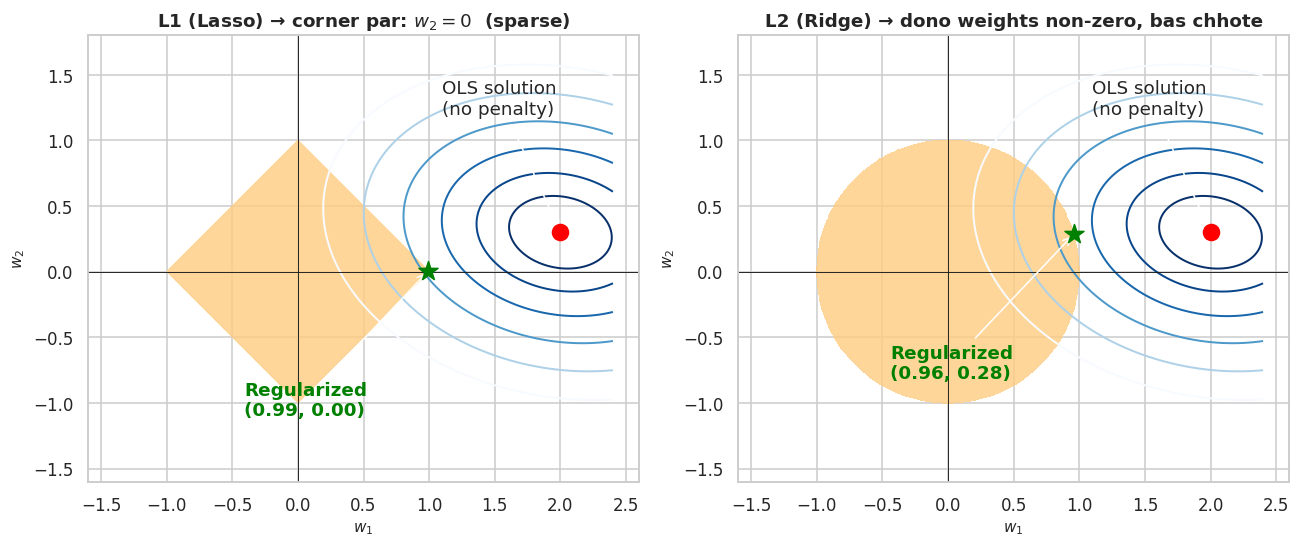

In [ ]:
g = np.linspace(-2.4, 2.4, 700); W1, W2 = np.meshgrid(g, g)
w0 = np.array([2.0, 0.3]); A = np.array([[1.0, 0.2], [0.2, 2.0]])
D1, D2 = W1 - w0[0], W2 - w0[1]
L = A[0, 0] * D1**2 + 2 * A[0, 1] * D1 * D2 + A[1, 1] * D2**2

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, kind in zip(axes, ["L1", "L2"]):
    mask = (np.abs(W1) + np.abs(W2) <= 1) if kind == "L1" else (W1**2 + W2**2 <= 1)
    ax.contour(W1, W2, L, levels=[.15, .4, .8, 1.4, 2.2, 3.2], cmap="Blues_r", linewidths=1.3)
    ax.contourf(W1, W2, mask.astype(float), levels=[.5, 1.5], colors=["#ffcc80"], alpha=.8)
    idx = np.argmin(np.where(mask, L, np.inf)); sol = (W1.ravel()[idx], W2.ravel()[idx])
    ax.scatter(*w0, s=110, c="red", zorder=5); ax.annotate("OLS solution\n(no penalty)", w0, xytext=(w0[0] - .9, w0[1] + .9), arrowprops=dict(arrowstyle="->"))
    ax.scatter(*sol, s=170, c="green", marker="*", zorder=6); ax.annotate(f"Regularized\n({sol[0]:.2f}, {sol[1]:.2f})", sol, xytext=(sol[0] - 1.4, sol[1] - 1.1), arrowprops=dict(arrowstyle="->"), color="green", fontweight="bold")
    ax.axhline(0, color="k", lw=.6); ax.axvline(0, color="k", lw=.6); ax.set_aspect("equal"); ax.set_xlim(-1.6, 2.6); ax.set_ylim(-1.6, 1.8)
    ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$")
    ax.set_title("L1 (Lasso) → corner par: $w_2 = 0$  (sparse)" if kind == "L1" else "L2 (Ridge) → dono weights non-zero, bas chhote")
plt.tight_layout(); plt.show()

### 3.5 Classification mein bhi wahi: Logistic Regression (`C = 1/λ`) — breast-cancer dataset

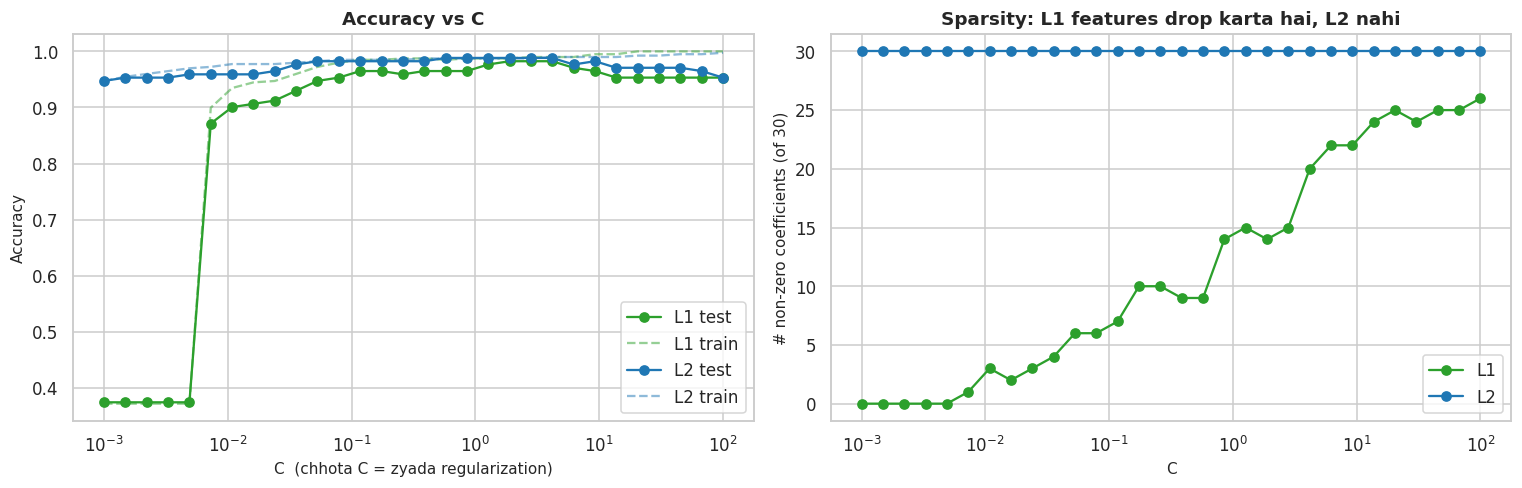

In [ ]:
bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=.3, stratify=bc.target, random_state=RNG)
sc = StandardScaler().fit(Xb_tr); Xb_tr, Xb_te = sc.transform(Xb_tr), sc.transform(Xb_te)
Cs = np.logspace(-3, 2, 30); rec = []
for C in Cs:
    for pen in ["l1", "l2"]:
        lr = LogisticRegression(penalty=pen, C=C, solver="liblinear", max_iter=5000).fit(Xb_tr, yb_tr)
        rec.append(dict(C=C, penalty=pen.upper(), train=lr.score(Xb_tr, yb_tr), test=lr.score(Xb_te, yb_te), nonzero=(lr.coef_ != 0).sum()))
rec = pd.DataFrame(rec)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for pen, c in [("L1", "#2ca02c"), ("L2", "#1f77b4")]:
    s = rec[rec.penalty == pen]
    axes[0].semilogx(s.C, s.test, "o-", color=c, label=f"{pen} test"); axes[0].semilogx(s.C, s.train, "--", color=c, alpha=.5, label=f"{pen} train")
    axes[1].semilogx(s.C, s.nonzero, "o-", color=c, label=pen)
axes[0].set_xlabel("C  (chhota C = zyada regularization)"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].set_title("Accuracy vs C")
axes[1].set_xlabel("C"); axes[1].set_ylabel("# non-zero coefficients (of 30)"); axes[1].legend(); axes[1].set_title("Sparsity: L1 features drop karta hai, L2 nahi")
plt.tight_layout(); plt.show()

---
# Part 4️⃣ Ensemble Methods — Bagging

**Ensemble = bahut saare "weak/unstable" models ko combine karke ek strong model.** Do main families:

| | **Bagging** (Bootstrap Aggregating) | **Boosting** |
|---|---|---|
| Training | **Parallel** – models independent | **Sequential** – har model pichhli galtiyan sudharta hai |
| Data | Har model ko *bootstrap sample* (with replacement) | Poora data, par errors/residuals par focus |
| Base learner | Deep / low-bias, high-variance trees | Shallow / high-bias trees (stumps, depth 3–8) |
| Reduces | **Variance** ↓ | Mainly **Bias** ↓ (variance bhi, with regularization) |
| Combine | Average / majority vote | Weighted sum |
| Examples | Bagging, **Random Forest** | AdaBoost, Gradient Boosting, **XGBoost**, **LightGBM**, CatBoost |
| Overfit risk | Low (more trees ≠ overfit) | Higher (zyada rounds → overfit; early stopping zaroori) |

### Bagging ka math
$B$ models, har ek ka variance $\sigma^2$ aur pairwise correlation $\rho$ ho, to average ka variance:
$$\operatorname{Var}\!\Big(\tfrac1B\sum_b \hat f_b\Big)=\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2$$
$B\to\infty$ par second term gayab → sirf $\rho\sigma^2$ bachta hai. **Random Forest** har split par random feature subset leta hai taaki $\rho$ aur kam ho.

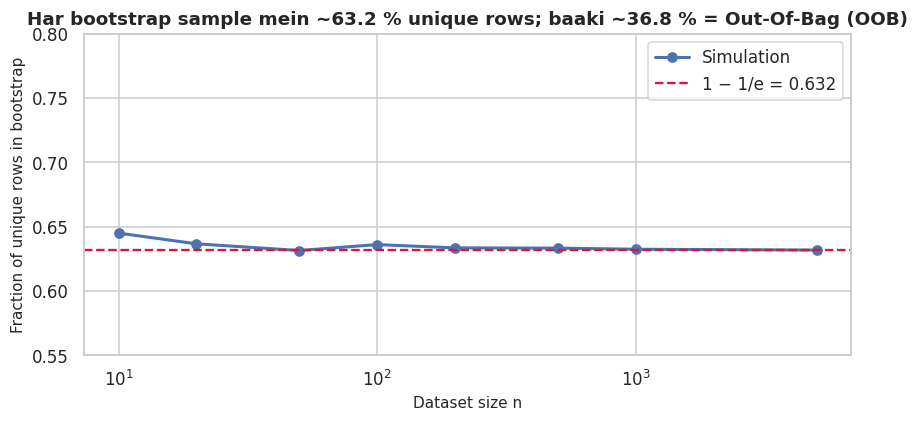

In [ ]:
# Bootstrap sample mein kitne unique rows hote hain?  → 1 - 1/e ≈ 63.2 %
rng = np.random.RandomState(0)
ns = [10, 20, 50, 100, 200, 500, 1000, 5000]
frac = [np.mean([len(np.unique(rng.randint(0, n, n))) / n for _ in range(300)]) for n in ns]
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(ns, frac, "o-", lw=2, label="Simulation")
ax.axhline(1 - 1 / np.e, color="crimson", ls="--", label="1 − 1/e = 0.632")
ax.set_xlabel("Dataset size n"); ax.set_ylabel("Fraction of unique rows in bootstrap"); ax.set_ylim(.55, .8)
ax.set_title("Har bootstrap sample mein ~63.2 % unique rows; baaki ~36.8 % = Out-Of-Bag (OOB)"); ax.legend()
plt.tight_layout(); plt.show()

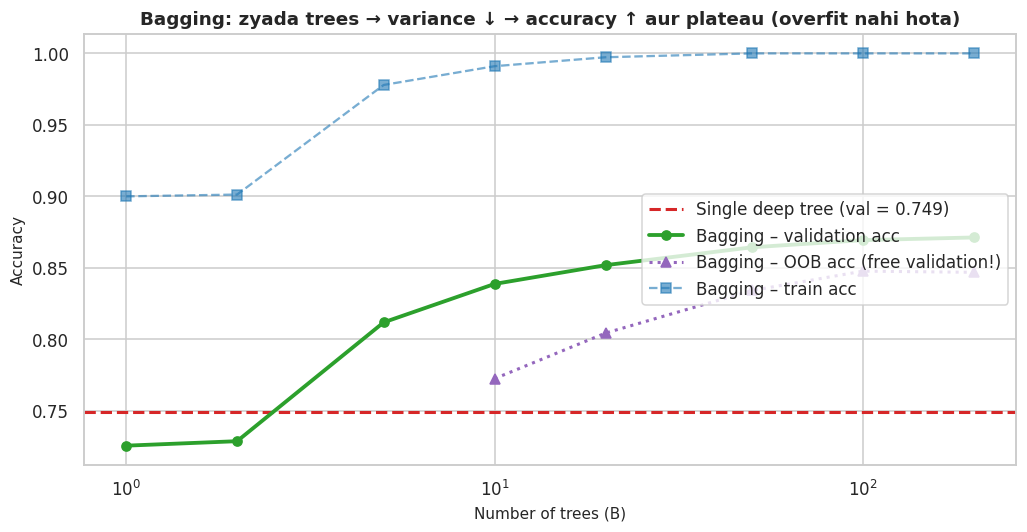

In [ ]:
# Single tree vs Bagging (n_estimators badhate hue)
n_list = [1, 2, 5, 10, 20, 50, 100, 200]
rows = []
for n in n_list:
    bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RNG), n_estimators=n,
                            oob_score=(n >= 10), n_jobs=-1, random_state=RNG).fit(X_train, y_train)
    rows.append(dict(n=n, train=bag.score(X_train, y_train), val=bag.score(X_val, y_val),
                     oob=bag.oob_score_ if n >= 10 else np.nan))
bg = pd.DataFrame(rows)
tree = DecisionTreeClassifier(random_state=RNG).fit(X_train, y_train)
tree_val = tree.score(X_val, y_val)

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.axhline(tree_val, color="#d62728", ls="--", lw=2, label=f"Single deep tree (val = {tree_val:.3f})")
ax.semilogx(bg.n, bg.val, "o-", color="#2ca02c", lw=2.5, label="Bagging – validation acc")
ax.semilogx(bg.n, bg.oob, "^:", color="#9467bd", lw=2, label="Bagging – OOB acc (free validation!)")
ax.semilogx(bg.n, bg.train, "s--", color="#1f77b4", alpha=.6, label="Bagging – train acc")
ax.set_xlabel("Number of trees (B)"); ax.set_ylabel("Accuracy"); ax.legend(loc="center right")
ax.set_title("Bagging: zyada trees → variance ↓ → accuracy ↑ aur plateau (overfit nahi hota)")
plt.tight_layout(); plt.show()

In [ ]:
# Bagging vs Random Forest vs single tree
models["Decision Tree"] = tree; evaluate("Decision Tree", tree)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RNG), n_estimators=200, n_jobs=-1, random_state=RNG).fit(X_train, y_train)
evaluate("Bagging (200 trees)", bag)
rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True, n_jobs=-1, random_state=RNG).fit(X_train, y_train)
evaluate("Random Forest (300)", rf)
print(f"Random Forest OOB score = {rf.oob_score_:.4f}  (test acc = {results['Random Forest (300)']['Test_Acc']:.4f}) → OOB ≈ test, bina alag validation set ke!")
display(pd.DataFrame(results).T.round(4))

Random Forest OOB score = 0.8708  (test acc = 0.8875) → OOB ≈ test, bina alag validation set ke!


,Train_Acc,Test_Acc,Gap,Test_AUC
Decision Tree,1.0,0.7631,0.2369,0.7631
Bagging (200 trees),1.0,0.8738,0.1262,0.9378
Random Forest (300),1.0,0.8875,0.1125,0.9462


**📌 Observation:** Single tree ki train accuracy ≈ 100 % par test kam → high variance. Bagging/RF train par bhi ≈ 100 % ho sakte hain, par **test accuracy kaafi behtar** — kyunki averaging ne variance kam kar diya. Bias lagbhag wahi raha.

---
# Part 5️⃣ Boosting — AdaBoost → Gradient Boosting → XGBoost → LightGBM

**Idea:** ek *weak learner* (chhota tree) lo, uski galtiyan dekho, agla tree un galtiyon ko theek kare — aise $M$ rounds.

$$
F_0(x)=\text{const},\qquad F_m(x)=F_{m-1}(x)+\eta\, h_m(x),\qquad h_m \;\text{fits the negative gradient (residuals) of the loss at }F_{m-1}
$$

$\eta$ = **learning rate** (shrinkage). Chhota $\eta$ + zyada trees = slow but safe (better generalization).

### 5.1 Gradient Boosting *from scratch* (regression, squared loss → residual fitting)
Shallow trees (depth 2) ek-ek karke residuals fit karte hain. Dekho kaise ensemble sine curve ko round-by-round seekhta hai:

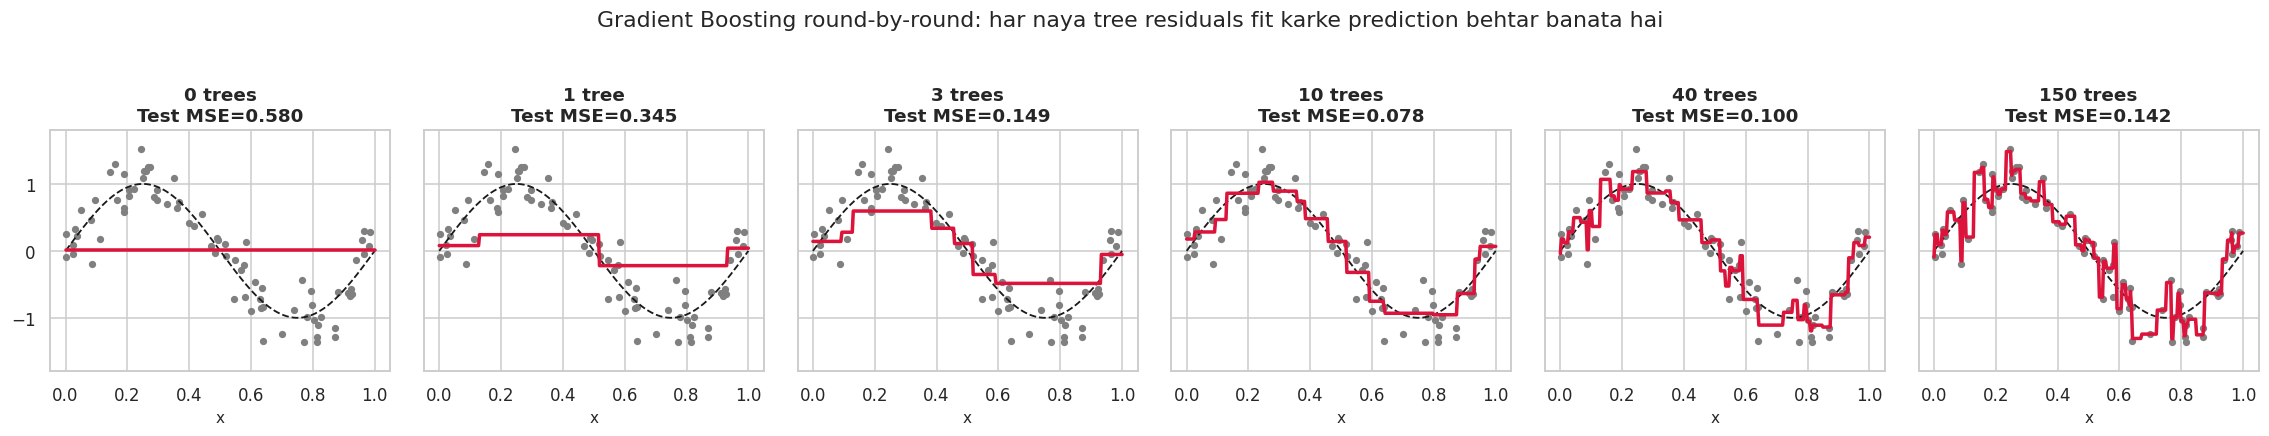

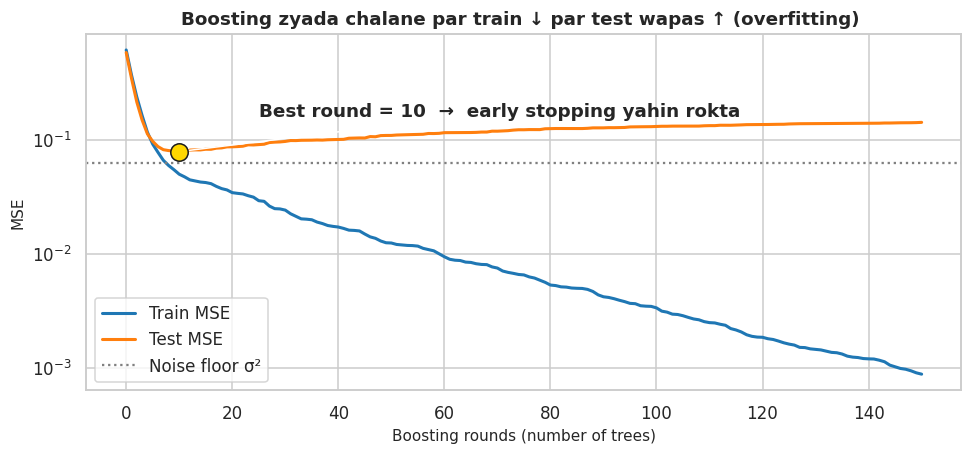

In [ ]:
xb_tr, yb_tr_ = make_data(80, 0.25, seed=5)
xb_te, yb_te_ = make_data(400, 0.25, seed=77)
LR_, DEPTH, M = 0.3, 2, 150
f0 = yb_tr_.mean(); pred_tr = np.full_like(yb_tr_, f0); trees_ = []
for _ in range(M):
    resid = yb_tr_ - pred_tr                                     # negative gradient of 1/2 (y - F)^2
    t = DecisionTreeRegressor(max_depth=DEPTH, random_state=0).fit(xb_tr[:, None], resid)
    pred_tr = pred_tr + LR_ * t.predict(xb_tr[:, None]); trees_.append(t)

def gb_predict(xq, k):
    out = np.full(len(xq), f0)
    for t in trees_[:k]: out = out + LR_ * t.predict(xq[:, None])
    return out

ks = [0, 1, 3, 10, 40, 150]
fig, axes = plt.subplots(1, 6, figsize=(21, 3.8), sharey=True)
for ax, k in zip(axes, ks):
    ax.scatter(xb_tr, yb_tr_, c="gray", s=14, label="data")
    ax.plot(x_grid, f_true(x_grid), "k--", lw=1.2)
    ax.plot(x_grid, gb_predict(x_grid, k), color="crimson", lw=2.3)
    ax.set_title(f"{k} tree{'s' if k != 1 else ''}\nTest MSE={mean_squared_error(yb_te_, gb_predict(xb_te, k)):.3f}")
    ax.set_xlabel("x"); ax.set_ylim(-1.8, 1.8)
fig.suptitle("Gradient Boosting round-by-round: har naya tree residuals fit karke prediction behtar banata hai", y=1.04)
plt.tight_layout(); plt.show()

tr_err = [mean_squared_error(yb_tr_, gb_predict(xb_tr, k)) for k in range(M + 1)]
te_err = [mean_squared_error(yb_te_, gb_predict(xb_te, k)) for k in range(M + 1)]
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(tr_err, label="Train MSE", color="#1f77b4", lw=2); ax.plot(te_err, label="Test MSE", color="#ff7f0e", lw=2)
bk = int(np.argmin(te_err)); ax.scatter(bk, te_err[bk], s=130, c="gold", edgecolor="k", zorder=5)
ax.annotate(f"Best round = {bk}  →  early stopping yahin rokta", (bk, te_err[bk]), xytext=(bk + 15, te_err[bk] + .08), arrowprops=dict(arrowstyle="->"), fontweight="bold")
ax.axhline(.25 ** 2, color="gray", ls=":", label="Noise floor σ²"); ax.set_yscale("log")
ax.set_xlabel("Boosting rounds (number of trees)"); ax.set_ylabel("MSE"); ax.legend(); ax.set_title("Boosting zyada chalane par train ↓ par test wapas ↑ (overfitting) ")
plt.tight_layout(); plt.show()

### 5.2 Sklearn ke AdaBoost & GradientBoosting
- **AdaBoost**: misclassified samples ka *weight* badhata hai, agla stump un par focus karta hai.
- **Gradient Boosting**: residual / gradient fit karta hai (upar jaisa).

In [ ]:
t0 = time.time()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=300, learning_rate=0.5, random_state=RNG).fit(X_train, y_train)
evaluate("AdaBoost", ada); t_ada = time.time() - t0
t0 = time.time()
gbc = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, random_state=RNG).fit(X_train, y_train)
evaluate("Gradient Boosting (sklearn)", gbc); t_gbc = time.time() - t0
print(f"AdaBoost fit {t_ada:.1f}s | sklearn GB fit {t_gbc:.1f}s")
display(pd.DataFrame(results).T.round(4))

AdaBoost fit 21.4s | sklearn GB fit 21.5s


,Train_Acc,Test_Acc,Gap,Test_AUC
Decision Tree,1.0000,0.7631,0.2369,0.7631
Bagging (200 trees),1.0000,0.8738,0.1262,0.9378
Random Forest (300),1.0000,0.8875,0.1125,0.9462
AdaBoost,0.8288,0.7962,0.0325,0.8769
Gradient Boosting (sklearn),0.9375,0.8656,0.0719,0.9358


### 5.3 🚀 XGBoost (eXtreme Gradient Boosting)

**Kya special hai?**
1. **Regularized objective** – loss + $\gamma T + \tfrac12\lambda\sum w_j^2 + \alpha\sum|w_j|$ ($T$ = leaves, $w_j$ = leaf weights) → built-in L1/L2 aur tree-complexity penalty
2. **2nd-order (Newton) approximation** – gradient + hessian dono use karta hai → behtar splits
3. **Sparsity-aware split finding** – missing values ko khud handle karta hai
4. **Level-wise (depth-wise) tree growth**, histogram-based `tree_method="hist"` fast training
5. Column/row **subsampling**, **early stopping**, parallel & cache-optimized

| Parameter | Role | Overfit rokne ke liye |
|---|---|---|
| `n_estimators`, `learning_rate` (η) | Rounds aur step size | η ↓, rounds ↑ + early stopping |
| `max_depth` | Tree depth | ↓ (3–6) |
| `min_child_weight` | Leaf mein min hessian sum | ↑ |
| `gamma` | Split ke liye min loss reduction | ↑ |
| `subsample`, `colsample_bytree` | Row / column sampling | 0.6–0.9 |
| `reg_lambda` (L2), `reg_alpha` (L1) | Leaf-weight penalty | ↑ |

XGBoost: best_iteration = 845 (of max 1000)  | fit time 3.01s
{'Train_Acc': 0.991875, 'Test_Acc': 0.886875, 'Gap': 0.10499999999999998, 'Test_AUC': np.float64(0.9502175122350632)}


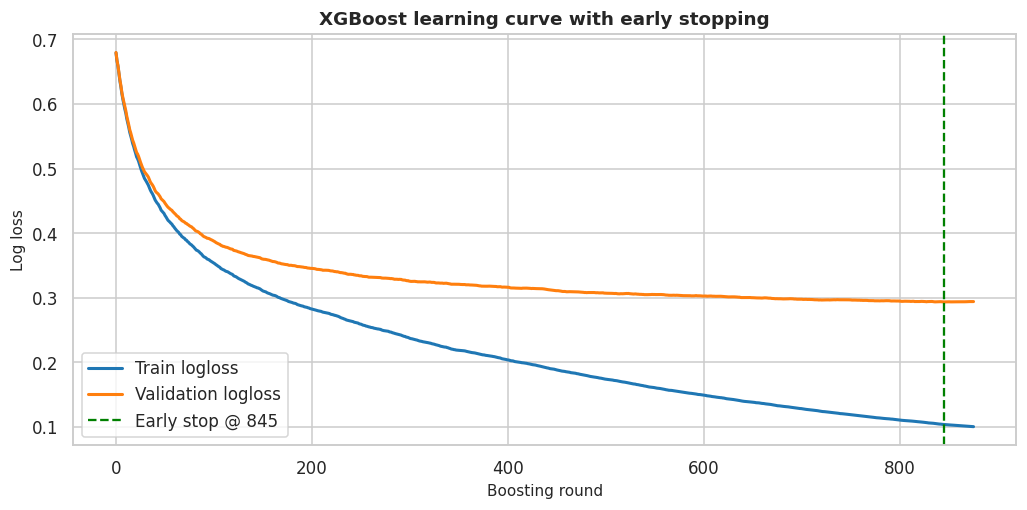

In [ ]:
xgbm = XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=4, min_child_weight=3,
                     subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=0.0, gamma=0.0,
                     eval_metric="logloss", early_stopping_rounds=30, tree_method="hist",
                     random_state=RNG, n_jobs=-1)
t0 = time.time()
xgbm.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
t_xgb = time.time() - t0
print(f"XGBoost: best_iteration = {xgbm.best_iteration} (of max 1000)  | fit time {t_xgb:.2f}s")
print(evaluate("XGBoost", xgbm))

ev = xgbm.evals_result(); k_tr, k_va = list(ev.keys())[:2]; metric = list(ev[k_va].keys())[0]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(ev[k_tr][metric], label="Train logloss", color="#1f77b4", lw=2)
ax.plot(ev[k_va][metric], label="Validation logloss", color="#ff7f0e", lw=2)
ax.axvline(xgbm.best_iteration, color="green", ls="--", label=f"Early stop @ {xgbm.best_iteration}")
ax.set_xlabel("Boosting round"); ax.set_ylabel("Log loss"); ax.set_title("XGBoost learning curve with early stopping"); ax.legend()
plt.tight_layout(); plt.show()

### 5.4 ⚡ LightGBM (Light Gradient Boosting Machine)

**Kya special hai?**
1. **Leaf-wise (best-first) growth** – XGBoost level-wise grow karta hai, LightGBM wo leaf split karta hai jisse loss sabse zyada kam ho → same #leaves par kam loss (par overfit ka risk → `num_leaves`, `min_child_samples` control karo)
2. **Histogram-based** split finding (features ko bins mein) → tez + kam memory
3. **GOSS** (Gradient-based One-Side Sampling): bade-gradient wale samples rakhta hai, chhote ka sample leta hai
4. **EFB** (Exclusive Feature Bundling): mutually-exclusive sparse features bundle
5. Native **categorical feature** support

```
XGBoost (level-wise)            LightGBM (leaf-wise)
      ●                               ●
    ┌─┴─┐                           ┌─┴─┐
    ●   ●        vs                 ●   ◍   ← sirf best leaf grow hota hai
  ┌─┴┐ ┌┴─┐                       ┌─┴┐
  ●  ● ●  ●                       ◍  ●
```

| XGBoost | LightGBM | Note |
|---|---|---|
| `max_depth` | `num_leaves` (main!), `max_depth` | LGBM mein `num_leaves < 2^max_depth` rakho |
| `min_child_weight` | `min_child_samples`, `min_sum_hessian_in_leaf` | |
| `subsample` | `subsample` + `subsample_freq` | LGBM mein `subsample_freq=1` zaroori |
| `colsample_bytree` | `colsample_bytree` | |
| `reg_lambda` / `reg_alpha` | `reg_lambda` / `reg_alpha` | L2 / L1 |
| `gamma` | `min_split_gain` | |

LightGBM: best_iteration = 400 (of max 1000) | fit time 4.25s
{'Train_Acc': 0.9997916666666666, 'Test_Acc': 0.895625, 'Gap': 0.10416666666666663, 'Test_AUC': np.float64(0.9522738779056321)}


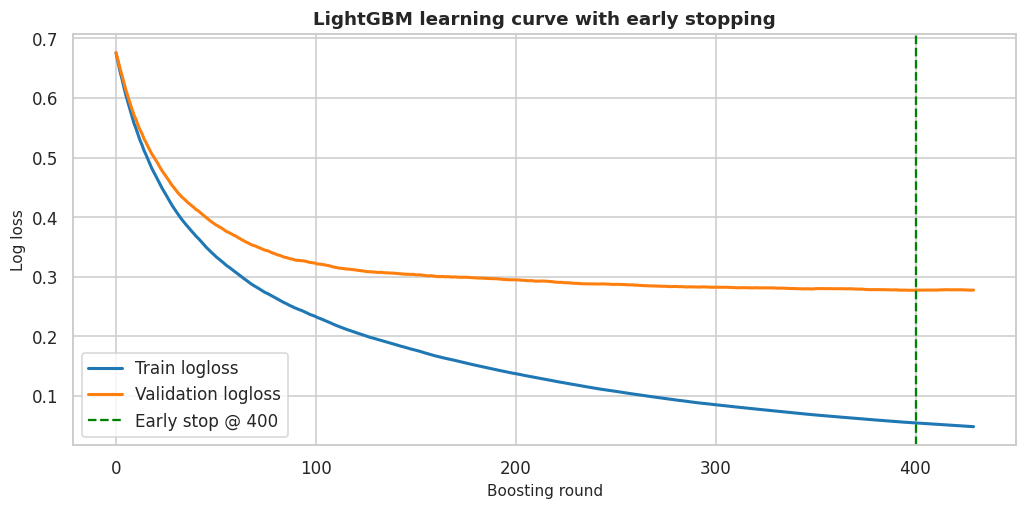

In [ ]:
lgbm = LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, min_child_samples=20,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, reg_alpha=0.0,
                      random_state=RNG, n_jobs=-1, verbose=-1)
t0 = time.time()
lgbm.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], eval_metric="binary_logloss",
         callbacks=[lgb.early_stopping(30, verbose=False)])
t_lgb = time.time() - t0
print(f"LightGBM: best_iteration = {lgbm.best_iteration_} (of max 1000) | fit time {t_lgb:.2f}s")
print(evaluate("LightGBM", lgbm))

ev = lgbm.evals_result_; k_tr, k_va = list(ev.keys())[:2]; metric = "binary_logloss" if "binary_logloss" in ev[k_va] else list(ev[k_va].keys())[0]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(ev[k_tr][metric], label="Train logloss", color="#1f77b4", lw=2)
ax.plot(ev[k_va][metric], label="Validation logloss", color="#ff7f0e", lw=2)
ax.axvline(lgbm.best_iteration_, color="green", ls="--", label=f"Early stop @ {lgbm.best_iteration_}")
ax.set_xlabel("Boosting round"); ax.set_ylabel("Log loss"); ax.set_title("LightGBM learning curve with early stopping"); ax.legend()
plt.tight_layout(); plt.show()

### 5.5 Feature importance — XGBoost vs LightGBM (gain-based)

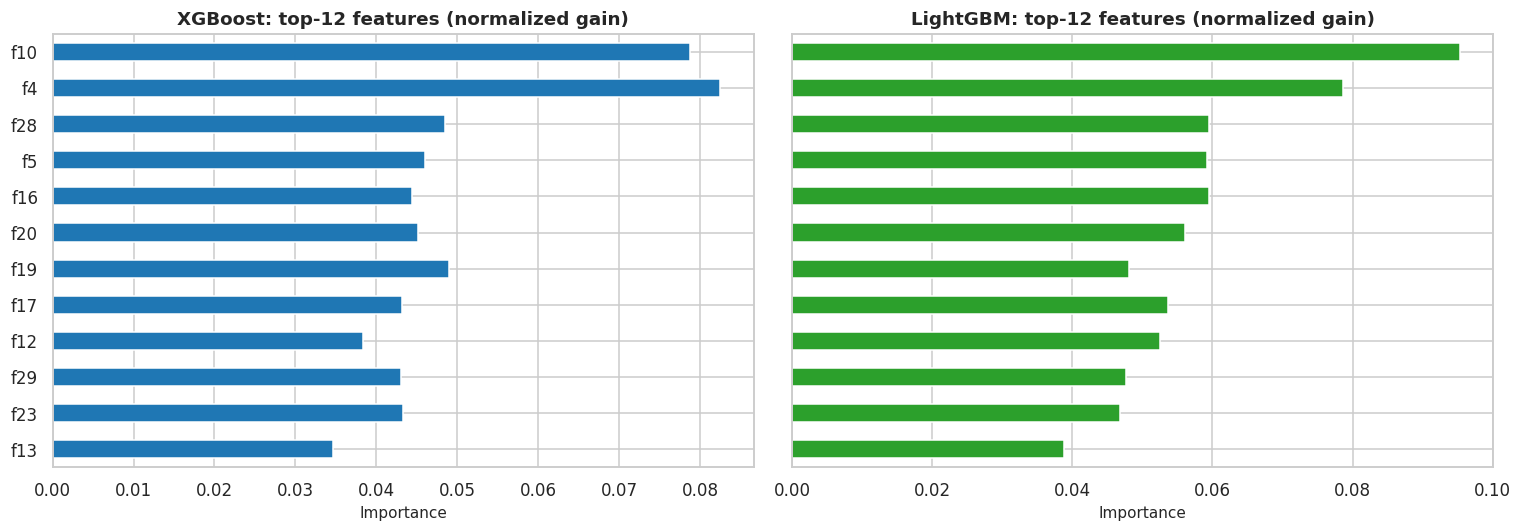

In [ ]:
imp = pd.DataFrame({"XGBoost": xgbm.get_booster().get_score(importance_type="gain"),
                    "LightGBM": pd.Series(lgbm.booster_.feature_importance("gain"), index=lgbm.booster_.feature_name())}).fillna(0)
imp = imp / imp.sum()
top = imp.mean(axis=1).sort_values(ascending=False).head(12).index
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, c, col in zip(axes, ["XGBoost", "LightGBM"], ["#1f77b4", "#2ca02c"]):
    imp.loc[top, c].iloc[::-1].plot.barh(ax=ax, color=col); ax.set_title(f"{c}: top-12 features (normalized gain)"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

### 5.6 Speed benchmark: bade dataset (40 000 × 40) par
Same #trees (300), `learning_rate=0.1`. Bagging-style Random Forest ko bhi reference ke liye add kiya.

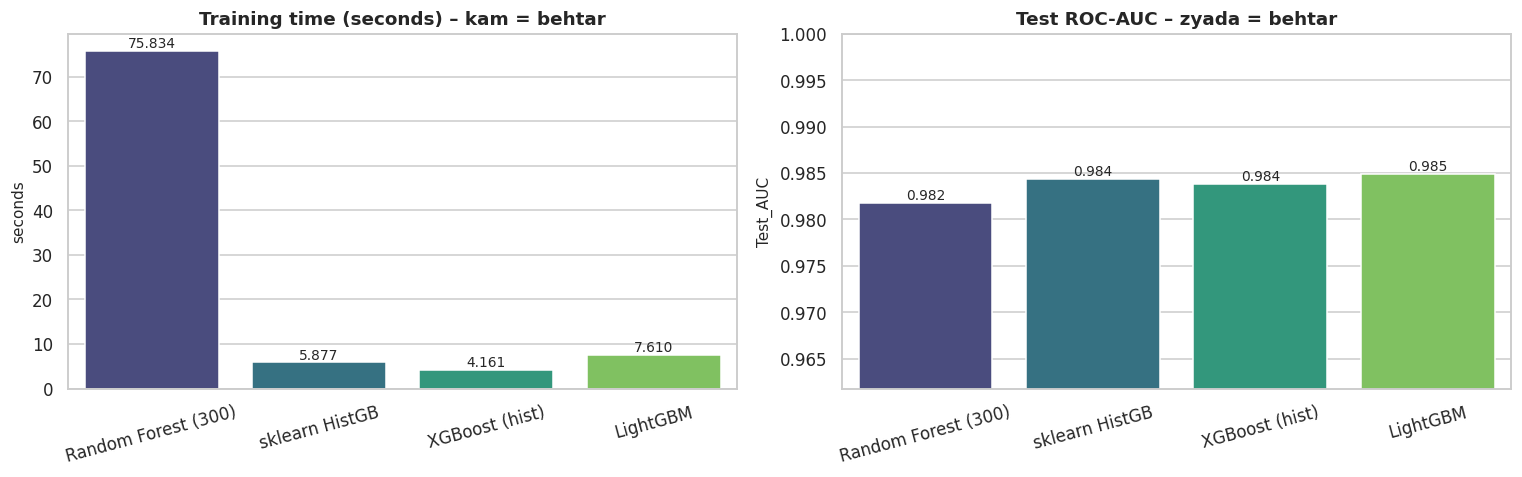

,Model,Fit_time_s,Test_AUC,Test_Acc
0,Random Forest (300),75.8336,0.9818,0.9497
1,sklearn HistGB,5.8774,0.9844,0.9641
2,XGBoost (hist),4.1607,0.9839,0.9644
3,LightGBM,7.6097,0.9849,0.9692


In [ ]:
Xs, ys = make_classification(n_samples=40000, n_features=40, n_informative=15, n_redundant=5, flip_y=0.03, random_state=1)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=.25, random_state=1)
bench = {"Random Forest (300)": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=1),
         "sklearn HistGB": HistGradientBoostingClassifier(max_iter=300, learning_rate=.1, random_state=1),
         "XGBoost (hist)": XGBClassifier(n_estimators=300, learning_rate=.1, max_depth=6, tree_method="hist", n_jobs=-1, random_state=1),
         "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=.1, num_leaves=63, n_jobs=-1, random_state=1, verbose=-1)}
bres = []
for n, m in bench.items():
    t0 = time.time(); m.fit(Xs_tr, ys_tr); dt = time.time() - t0
    bres.append(dict(Model=n, Fit_time_s=dt, Test_AUC=roc_auc_score(ys_te, m.predict_proba(Xs_te)[:, 1]), Test_Acc=m.score(Xs_te, ys_te)))
bres = pd.DataFrame(bres)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
pal = sns.color_palette("viridis", len(bres))
sns.barplot(data=bres, x="Model", y="Fit_time_s", ax=axes[0], palette=pal); axes[0].set_title("Training time (seconds) – kam = behtar"); axes[0].set_ylabel("seconds")
sns.barplot(data=bres, x="Model", y="Test_AUC", ax=axes[1], palette=pal); axes[1].set_ylim(bres.Test_AUC.min() - .02, 1.0); axes[1].set_title("Test ROC-AUC – zyada = behtar")
for ax in axes:
    ax.tick_params(axis="x", rotation=15); ax.set_xlabel("")
    for p in ax.patches: ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()
display(bres.round(4))

### 5.7 Boosting mein Overfitting vs Regularization ⭐
Ab Part 2 + Part 3 ko boosting par apply karte hain. Same data, do configs: ek **unregularized deep** (overfit), ek **regularized shallow** (L1 + L2 + γ + subsampling + min_child_weight).

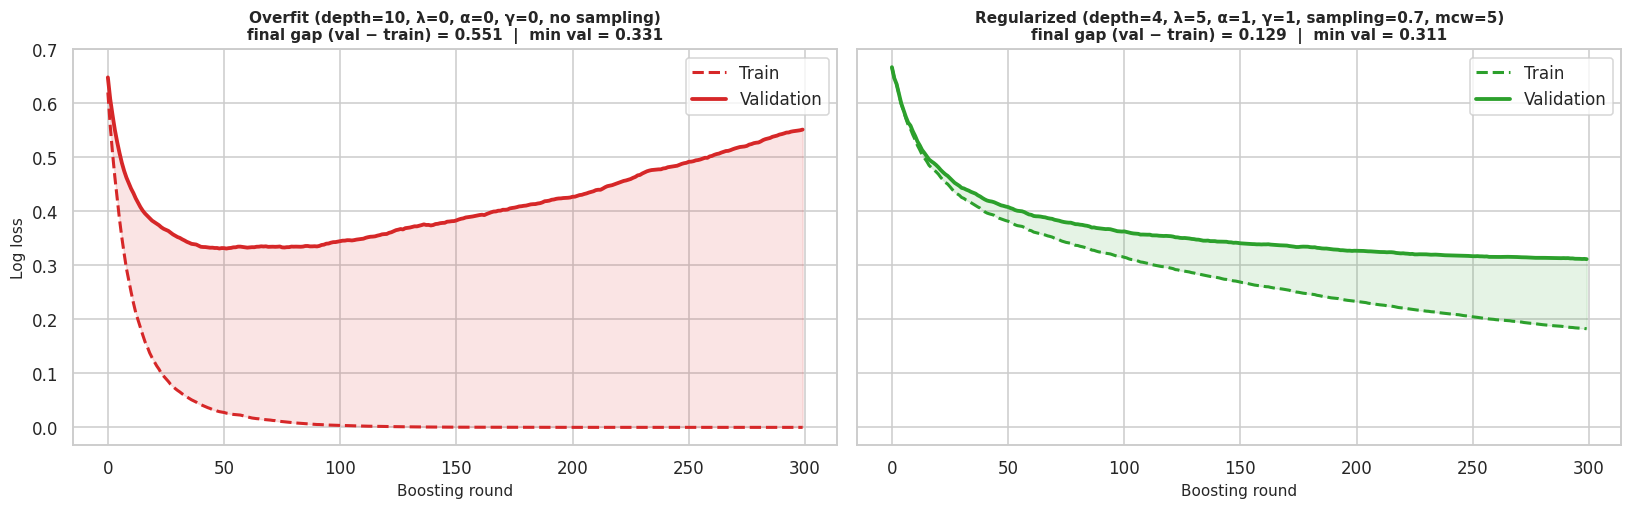

In [ ]:
cfgs = {"Overfit (depth=10, λ=0, α=0, γ=0, no sampling)": dict(max_depth=10, reg_lambda=0, reg_alpha=0, gamma=0, subsample=1.0, colsample_bytree=1.0, min_child_weight=0),
        "Regularized (depth=4, λ=5, α=1, γ=1, sampling=0.7, mcw=5)": dict(max_depth=4, reg_lambda=5, reg_alpha=1, gamma=1, subsample=.7, colsample_bytree=.7, min_child_weight=5)}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (name, kw), col in zip(axes, cfgs.items(), ["#d62728", "#2ca02c"]):
    m = XGBClassifier(n_estimators=300, learning_rate=0.1, eval_metric="logloss", tree_method="hist", random_state=RNG, n_jobs=-1, **kw)
    m.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
    e = m.evals_result(); a, b = list(e.keys())[:2]; mt = list(e[a].keys())[0]
    ax.plot(e[a][mt], "--", color=col, lw=2, label="Train"); ax.plot(e[b][mt], "-", color=col, lw=2.5, label="Validation")
    ax.fill_between(range(len(e[a][mt])), e[a][mt], e[b][mt], color=col, alpha=.12)
    ax.set_title(f"{name}\nfinal gap (val − train) = {e[b][mt][-1] - e[a][mt][-1]:.3f}  |  min val = {min(e[b][mt]):.3f}", fontsize=10)
    ax.set_xlabel("Boosting round"); ax.legend()
axes[0].set_ylabel("Log loss")
plt.tight_layout(); plt.show()

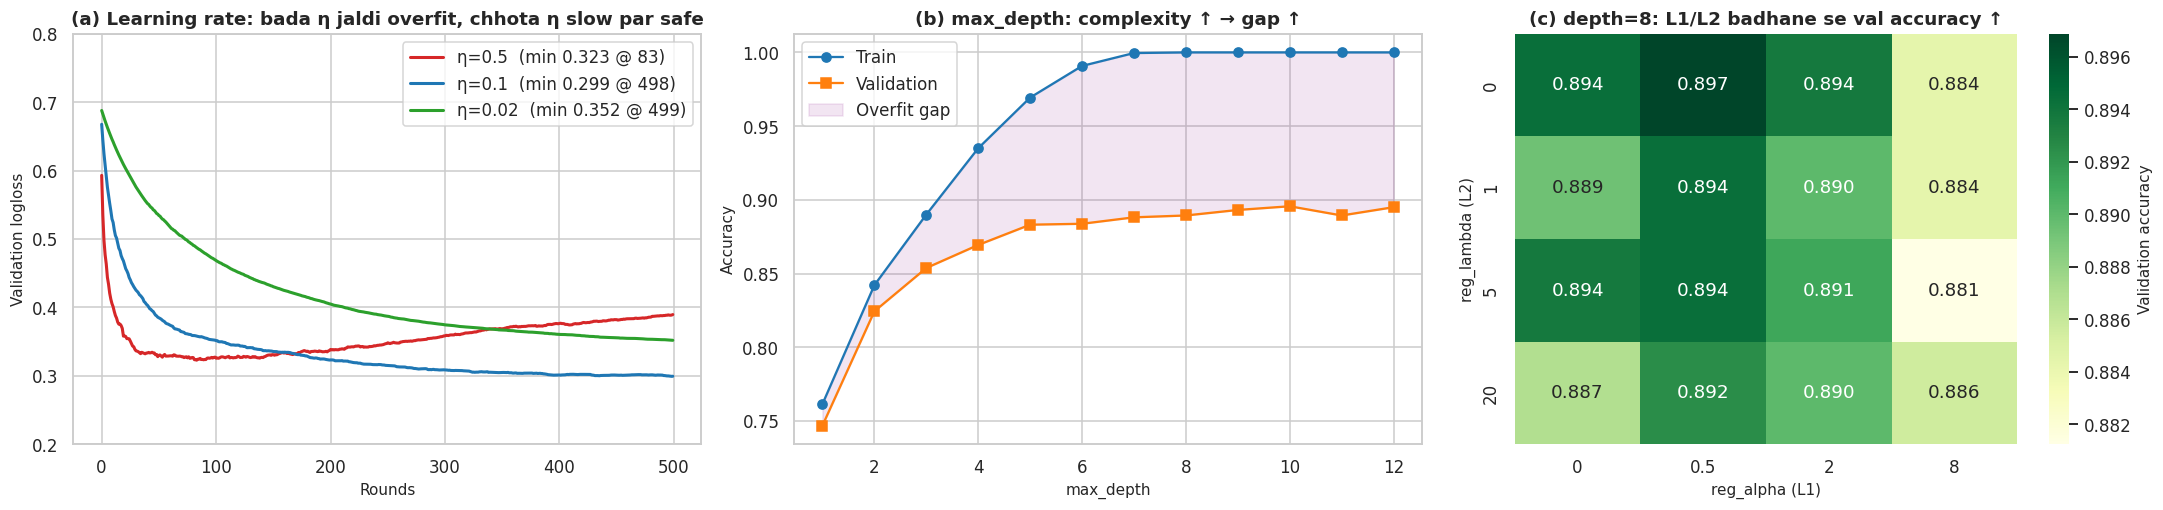

In [ ]:
# (a) learning_rate × n_estimators trade-off   (b) max_depth sweep  (c) L1 × L2 heat-map
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

# (a)
for lr_, c in zip([0.5, 0.1, 0.02], ["#d62728", "#1f77b4", "#2ca02c"]):
    m = XGBClassifier(n_estimators=500, learning_rate=lr_, max_depth=4, eval_metric="logloss", tree_method="hist", random_state=RNG, n_jobs=-1)
    m.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    cur = m.evals_result()["validation_0"]["logloss"]
    axes[0].plot(cur, color=c, lw=2, label=f"η={lr_}  (min {min(cur):.3f} @ {int(np.argmin(cur))})")
axes[0].set_ylim(.2, .8); axes[0].set_xlabel("Rounds"); axes[0].set_ylabel("Validation logloss"); axes[0].legend(); axes[0].set_title("(a) Learning rate: bada η jaldi overfit, chhota η slow par safe")

# (b)
rows = []
for d in range(1, 13):
    m = XGBClassifier(n_estimators=150, learning_rate=.1, max_depth=d, tree_method="hist", random_state=RNG, n_jobs=-1).fit(X_train, y_train)
    rows.append((d, m.score(X_train, y_train), m.score(X_val, y_val)))
r = np.array(rows)
axes[1].plot(r[:, 0], r[:, 1], "o-", label="Train", color="#1f77b4"); axes[1].plot(r[:, 0], r[:, 2], "s-", label="Validation", color="#ff7f0e")
axes[1].fill_between(r[:, 0], r[:, 2], r[:, 1], color="purple", alpha=.1, label="Overfit gap")
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("Accuracy"); axes[1].legend(); axes[1].set_title("(b) max_depth: complexity ↑ → gap ↑")

# (c)
lams, alps = [0, 1, 5, 20], [0, 0.5, 2, 8]
H = np.zeros((len(lams), len(alps)))
for i, l2 in enumerate(lams):
    for j, l1 in enumerate(alps):
        m = XGBClassifier(n_estimators=150, learning_rate=.1, max_depth=8, reg_lambda=l2, reg_alpha=l1, tree_method="hist", random_state=RNG, n_jobs=-1).fit(X_train, y_train)
        H[i, j] = m.score(X_val, y_val)
sns.heatmap(H, annot=True, fmt=".3f", cmap="YlGn", xticklabels=alps, yticklabels=lams, ax=axes[2], cbar_kws={"label": "Validation accuracy"})
axes[2].set_xlabel("reg_alpha (L1)"); axes[2].set_ylabel("reg_lambda (L2)"); axes[2].set_title("(c) depth=8: L1/L2 badhane se val accuracy ↑")
plt.tight_layout(); plt.show()

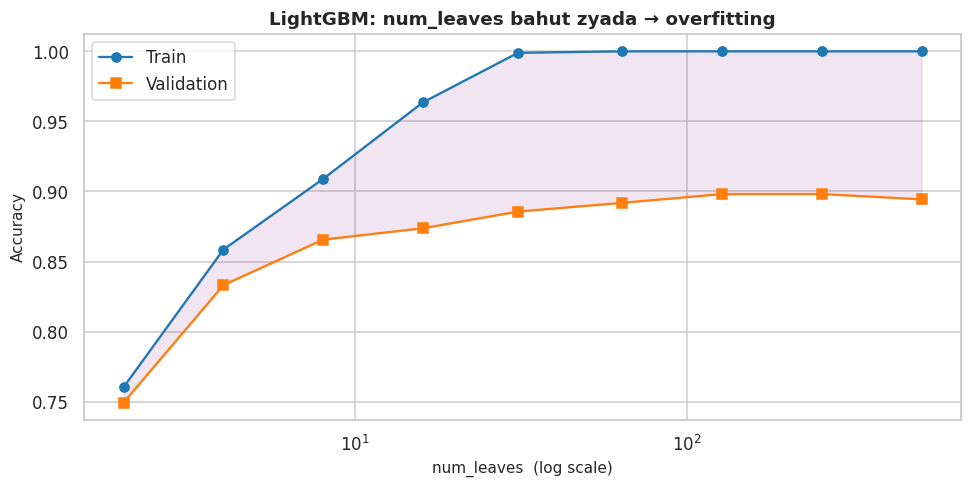

In [ ]:
# LightGBM: num_leaves (leaf-wise complexity knob) sweep
rows = []
for nl in [2, 4, 8, 16, 31, 64, 128, 256, 512]:
    m = LGBMClassifier(n_estimators=150, learning_rate=.1, num_leaves=nl, min_child_samples=5, random_state=RNG, n_jobs=-1, verbose=-1).fit(X_train, y_train)
    rows.append((nl, m.score(X_train, y_train), m.score(X_val, y_val)))
r = np.array(rows)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.semilogx(r[:, 0], r[:, 1], "o-", label="Train", color="#1f77b4"); ax.semilogx(r[:, 0], r[:, 2], "s-", label="Validation", color="#ff7f0e")
ax.fill_between(r[:, 0], r[:, 2], r[:, 1], color="purple", alpha=.1)
ax.set_xlabel("num_leaves  (log scale)"); ax.set_ylabel("Accuracy"); ax.legend(); ax.set_title("LightGBM: num_leaves bahut zyada → overfitting")
plt.tight_layout(); plt.show()

---
# Part 6️⃣ Final Comparison (test set)

,Train_Acc,Test_Acc,Gap,Test_AUC
LightGBM,0.9998,0.8956,0.1042,0.9523
XGBoost,0.9919,0.8869,0.1050,0.9502
Random Forest (300),1.0000,0.8875,0.1125,0.9462
Bagging (200 trees),1.0000,0.8738,0.1262,0.9378
Gradient Boosting (sklearn),0.9375,0.8656,0.0719,0.9358
AdaBoost,0.8288,0.7962,0.0325,0.8769
Decision Tree,1.0000,0.7631,0.2369,0.7631


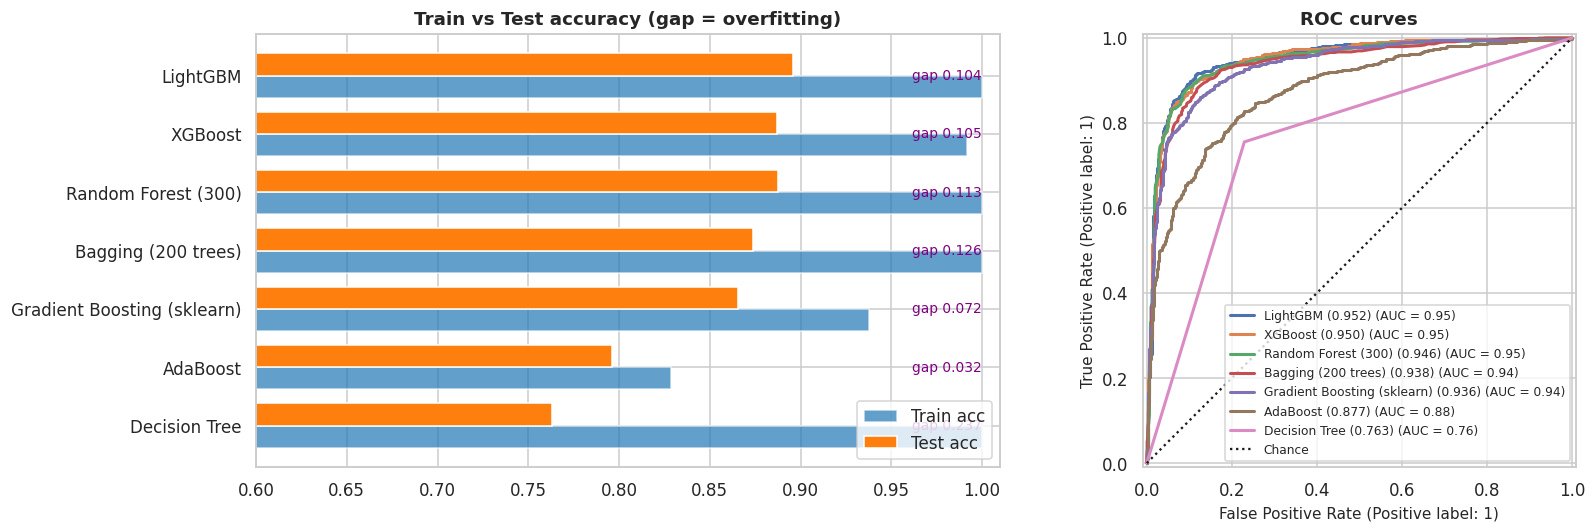

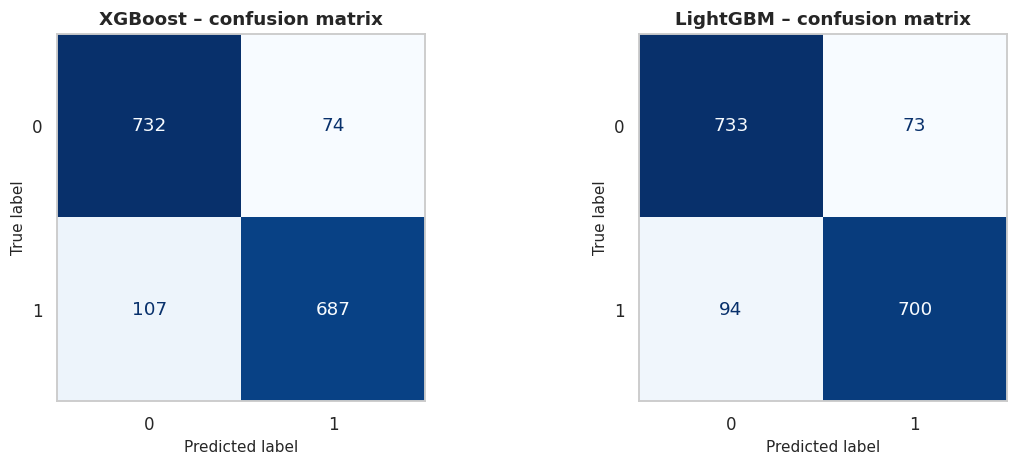

In [ ]:
res = pd.DataFrame(results).T.sort_values("Test_AUC", ascending=False)
display(res.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
order = res.index
w = .38; ix = np.arange(len(order))
axes[0].barh(ix + w / 2, res.loc[order, "Train_Acc"], w, label="Train acc", color="#1f77b4", alpha=.7)
axes[0].barh(ix - w / 2, res.loc[order, "Test_Acc"], w, label="Test acc", color="#ff7f0e")
axes[0].set_yticks(ix); axes[0].set_yticklabels(order); axes[0].invert_yaxis(); axes[0].set_xlim(.6, 1.01); axes[0].legend(loc="lower right")
axes[0].set_title("Train vs Test accuracy (gap = overfitting)")
for i, o in enumerate(order): axes[0].text(1.0, i, f"gap {res.loc[o,'Gap']:.3f}", va="center", ha="right", fontsize=9, color="purple")

for name in order:
    RocCurveDisplay.from_estimator(models[name], X_test, y_test, ax=axes[1], name=f"{name} ({res.loc[name,'Test_AUC']:.3f})", lw=2)
axes[1].plot([0, 1], [0, 1], "k:", label="Chance"); axes[1].set_title("ROC curves"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, n in zip(axes, ["XGBoost", "LightGBM"]):
    ConfusionMatrixDisplay.from_estimator(models[n], X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{n} – confusion matrix"); ax.grid(False)
plt.tight_layout(); plt.show()

## 🧾 Summary (revision ke liye)

**Bias–Variance**
- Error = Bias² + Variance + Noise. Complexity ↑ ⇒ Bias ↓, Variance ↑ ⇒ U-shaped test error.
- High bias = underfit (train & val dono kharab); High variance = overfit (train ≫ val).

**Overfitting / Underfitting**
- Detect: validation curve, learning curve, train–val gap.
- Fix: more data, regularization, early stopping, simpler model, bagging, feature selection, CV.

**Regularization**
- **L2 (Ridge)** – weights shrink; **L1 (Lasso)** – sparsity / feature selection; **Elastic Net** = dono.
- λ ↑ ⇒ bias ↑, variance ↓. λ ko cross-validation se choose karo.
- XGBoost / LightGBM mein `reg_lambda`, `reg_alpha`, `gamma/min_split_gain`, `min_child_weight`, `subsample`, `colsample`, `learning_rate`, `early_stopping`.

**Bagging vs Boosting**

| | Bagging / RF | Boosting (XGB / LGBM) |
|---|---|---|
| Main goal | Variance ↓ | Bias ↓ (phir regularize se variance control) |
| Trees | Deep, parallel | Shallow, sequential |
| Tuning difficulty | Easy | Zyada hyper-parameters |
| Accuracy on tabular data | Strong | Usually **state-of-the-art** |
| Risk | Kam overfit | Overfit ho sakta hai → early stopping |

**XGBoost vs LightGBM**
- XGBoost: level-wise, robust, regularization-rich, GPU support. LightGBM: leaf-wise, histogram + GOSS + EFB ⇒ **zyada tez / kam memory**, large data par best; chhote data par `num_leaves` control karo.
